# Approach 1 — IterativeImputer × all augmenters × all classifiers

**Hướng tiếp cận 1** = *impute → (full | img+reconstruct) generation → class-weight*, nhưng
imputer cố định là **sklearn `IterativeImputer` (MICE)**. Notebook benchmark:

- **Imputer:** `IterativeImputer` (MICE) — fit trên TRAIN, điền cả 6 biến số (light + heavy).
- **Kiến trúc sinh mẫu:** `full` (sinh trên toàn feature đã impute) **và** `imgrec`
  (sinh ảnh+cat, XGBRegressor tái tạo biến số; dòng gốc giữ raw).
- **Augmenters:** SMOTE/SMOTE-NC, G-SMOTE, ADASYN, SVMSMOTE, BorderlineSMOTE, KMeansSMOTE,
  CTGAN, CTAB-GAN+ (+ baseline `none`).
- **Classifiers:** XGBoost, LightGBM, CatBoost, RandomForest, ExtraTrees, IsolationForest,
  SVM, MLP — **+ Stacking** (top-3 theo F1 trên val).
- **Scope:** 8 bệnh, **class-weight ON**, split **Train 52% / Test 35% / Val 13%** (random row-level,
  **không group `subject_id`, bỏ qua time constraint**), **5 seed**.
- **Rò rỉ dữ liệu:** impute (fit) + augment **chỉ trên TRAIN**; **VAL chỉ để dò ngưỡng** (max F1 lớp 1);
  **TEST chỉ để chấm cuối**. `AUG_RATIO` cố định = 0.4 (không dò trên val).
- **Checkpoint/resume:** lưu CSV + ROC pickle **ngay sau mỗi classifier** (không đợi hết block);
  resume theo `(disease, arch, augmenter, classifier, seed)` → tắt bất ngờ chỉ mất **tối đa 1 classifier**.
  Trên **Kaggle**: checkpoint còn được **đẩy lên một Kaggle Dataset** (bền qua phiên) — cần Secrets
  `KAGGLE_USERNAME`/`KAGGLE_KEY` (hoặc `kaggle.json`). Lúc khởi động tự khôi phục từ Dataset/Input.
- **Mỗi scenario `(arch, augmenter)`** xong → vẽ **5 heatmap** (precision, recall, F1, AUROC, accuracy),
  ô in **mean ± std** qua các seed, + **đường ROC**.

> ⚠️ **Lưu ý:**
> - **IsolationForest** là mô hình phát hiện bất thường (unsupervised), ở đây được *dùng tạm* như classifier
>   (score bất thường → pseudo-proba); kết quả mang tính tham khảo.
> - **KMeansSMOTE** hay lỗi (không có cụm thiểu số đủ dày) → tự **fallback sang SMOTE** và in cảnh báo.
> - **SVM (SVC)** với `probability=True` chạy **chậm** trên dữ liệu lớn — dùng `QUICK=True` để thử nhanh.


In [9]:
# === Installs + clone CTAB-GAN+ (Colab / Kaggle) ===
import os, sys
def _sh(cmd):
    print('$', cmd); os.system(cmd)

IN_COLAB  = ('google.colab' in sys.modules) or os.path.isdir('/content')
IN_KAGGLE = os.path.isdir('/kaggle')
# Kaggle: bật Internet trong Settings để pip/git chạy được.
if IN_COLAB or IN_KAGGLE:
    _sh('pip -q install ctgan imbalanced-learn-extra imbalanced-learn xgboost lightgbm catboost')

# CTAB-GAN+ clone + the inverse log-transform assignment patch (cần Internet)
if not os.path.exists('CTAB-GAN-Plus'):
    _sh('git clone --depth 1 https://github.com/Team-TUD/CTAB-GAN-Plus.git')
_patch = os.path.join('CTAB-GAN-Plus', 'model', 'pipeline', 'data_preparation.py')
if os.path.exists(_patch):
    _txt = open(_patch, 'r', encoding='utf-8').read()
    _old = "                        df_sample[i].apply(lambda x: np.exp(x)) "
    _new = "                        df_sample[i] = df_sample[i].apply(lambda x: np.exp(x))"
    if _old in _txt:
        open(_patch, 'w', encoding='utf-8').write(_txt.replace(_old, _new))
        print('Patched CTAB-GAN+ inverse log-transform assignment.')
if os.path.isdir('CTAB-GAN-Plus') and os.path.abspath('CTAB-GAN-Plus') not in sys.path:
    sys.path.insert(0, os.path.abspath('CTAB-GAN-Plus'))


$ pip -q install ctgan imbalanced-learn-extra imbalanced-learn xgboost lightgbm catboost
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.5/74.5 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 59.1 MB/s eta 0:00:00
$ git clone --depth 1 https://github.com/Team-TUD/CTAB-GAN-Plus.git


Cloning into 'CTAB-GAN-Plus'...


Patched CTAB-GAN+ inverse log-transform assignment.


In [10]:
# === Working dir + data path + checkpoint location (Colab / Kaggle / local) ===
import os, glob
IN_KAGGLE = os.path.isdir('/kaggle')

if not IN_KAGGLE:
    # Colab: mount Drive và làm việc trong thư mục bền trên Drive
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        os.chdir('/content/drive/MyDrive/DataAug')   # đổi nếu thư mục Drive khác
    except Exception as e:
        print('Drive mount skipped:', e)
else:
    # Kaggle: output bền nằm ở /kaggle/working (nhớ Save Version để giữ qua các phiên)
    os.chdir('/kaggle/working')

# --- DATA_PATH: tìm file CSV sạch tự động (Kaggle để data ở /kaggle/input/<dataset>/) ---
_cands = ['x_ray_and_features_data(2).csv'] + sorted(
    glob.glob('/kaggle/input/**/x_ray_and_features_data(2).csv', recursive=True))
DATA_PATH = next((p for p in _cands if os.path.exists(p)), 'x_ray_and_features_data(2).csv')
# Nếu tự dò không ra trên Kaggle, set tay: DATA_PATH = '/kaggle/input/<ten-dataset>/x_ray_and_features_data.csv'

# Checkpoint/kết quả (bền). Trên Colab có ghi thêm bản tạm /content/results.
RESULTS_DIR  = 'results_approach1'
RESULTS_NAME = 'results_approach1_iterimp.csv'
ROC_NAME     = 'roc_approach1_iterimp.pkl'
os.makedirs(RESULTS_DIR, exist_ok=True)
print('cwd:', os.getcwd(), '| data:', DATA_PATH, '| exists:', os.path.exists(DATA_PATH))


cwd: /kaggle/working | data: /kaggle/input/datasets/tuanducngo/datasetorg/x_ray_and_features_data(2).csv | exists: True


In [11]:
# === Imports + load data + column groups ===
import io, math, time, pickle, warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tqdm
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              IsolationForest, StackingClassifier)
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score,
                             accuracy_score, roc_auc_score, roc_curve)
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer

from imblearn.over_sampling import (SMOTE, SMOTENC, ADASYN, SVMSMOTE,
                                    BorderlineSMOTE, KMeansSMOTE)
try:
    from imblearn_extra.gsmote import GeometricSMOTE
except Exception:
    try:
        from imblearn.over_sampling import GeometricSMOTE
    except Exception:
        GeometricSMOTE = None
        print('GeometricSMOTE unavailable -> "gsmote" will fall back to SMOTE')

from xgboost import XGBClassifier, XGBRegressor
try:
    from lightgbm import LGBMClassifier
except Exception:
    LGBMClassifier = None; print('LightGBM unavailable')
try:
    from catboost import CatBoostClassifier
except Exception:
    CatBoostClassifier = None; print('CatBoost unavailable')

df = pd.read_csv(DATA_PATH)

diseases    = ['pneumonia', 'tuberculosis', 'bronchitis', 'arthritis', 'fracture',
               'lung_cancer', 'scoliosis', 'lung_infection']
mimic_feats = ['diabete', 'age', 'hiv', 'oxygen', 'heart_rate', 'temperature',
               'hemoglobin', 'rbc', 'wbc', 'smoke', 'cough']
img_feats   = [str(x) for x in range(18)]
cat_feats   = ['diabete', 'hiv', 'smoke', 'cough']
num_light   = ['hemoglobin', 'rbc', 'wbc']
num_heavy   = ['oxygen', 'heart_rate', 'temperature']
full_feats  = img_feats + mimic_feats
AGE         = 'age'
SCOPE       = 'chained'   # imputer fills all 6; imgrec reconstructs light->heavy (chained)

data = df[img_feats + mimic_feats].copy()
print('rows:', len(data), '| features:', len(full_feats), '| diseases:', len(diseases))


rows: 29083 | features: 29 | diseases: 8


In [12]:
# === Split Train 52% / Test 35% / Val 13% (cached) + IterativeImputer (MICE), fit on TRAIN only ===
TRAIN_RATIO, TEST_RATIO_, VAL_RATIO = 0.52, 0.35, 0.13
_SPLIT_CACHE, _IMP_CACHE = {}, {}

HEAVY_VALID_RULES = {
    'oxygen':      {'low': 20, 'high': None, 'low_inclusive': False, 'high_inclusive': True},
    'heart_rate':  {'low': 30, 'high': None, 'low_inclusive': False, 'high_inclusive': True},
    'temperature': {'low': 55, 'high': 110,  'low_inclusive': True,  'high_inclusive': True},
}

def _apply_heavy_valid_ranges(x):
    x = x.copy()
    for col, rule in HEAVY_VALID_RULES.items():
        if col not in x.columns:
            continue
        vals = pd.to_numeric(x[col], errors='coerce')
        valid = vals.notna()
        lo, hi = rule.get('low'), rule.get('high')
        if lo is not None:
            valid &= (vals >= lo) if rule.get('low_inclusive', True) else (vals > lo)
        if hi is not None:
            valid &= (vals <= hi) if rule.get('high_inclusive', True) else (vals < hi)
        x[col] = vals.mask(vals.notna() & ~valid)
    return x

def get_split(seed):
    """Raw train/test/val (heavy outliers -> NaN). imgrec dùng bản raw này (không impute)."""
    if seed in _SPLIT_CACHE:
        return _SPLIT_CACHE[seed]
    idx = np.arange(len(data))
    tr, tmp = train_test_split(idx, test_size=(TEST_RATIO_ + VAL_RATIO), random_state=seed)
    te, va = train_test_split(tmp, test_size=VAL_RATIO / (TEST_RATIO_ + VAL_RATIO), random_state=seed)
    xtr_raw = _apply_heavy_valid_ranges(data.iloc[tr].reset_index(drop=True))
    xte_raw = _apply_heavy_valid_ranges(data.iloc[te].reset_index(drop=True))
    xva_raw = _apply_heavy_valid_ranges(data.iloc[va].reset_index(drop=True))
    _SPLIT_CACHE[seed] = (tr, te, va, xtr_raw, xte_raw, xva_raw)
    return _SPLIT_CACHE[seed]

IMP_CONTEXT = img_feats + cat_feats + [AGE]
IMP_NUMERIC = num_light + num_heavy

def iterative_impute_train_test(xtr, xte, seed):
    """MICE over context + 6 numerics. Fit on TRAIN; transform train & (test+val) once. NaN-free output."""
    cols = IMP_CONTEXT + IMP_NUMERIC
    a = xtr[cols].apply(pd.to_numeric, errors='coerce').reset_index(drop=True)
    b = xte[cols].apply(pd.to_numeric, errors='coerce').reset_index(drop=True)
    imp = IterativeImputer(random_state=seed, max_iter=10, sample_posterior=False)
    a_imp = pd.DataFrame(imp.fit_transform(a), columns=cols)
    b_imp = pd.DataFrame(imp.transform(b),     columns=cols)
    xtri = xtr.reset_index(drop=True).copy(); xtei = xte.reset_index(drop=True).copy()
    for c in IMP_NUMERIC:
        xtri[c] = a_imp[c].to_numpy(); xtei[c] = b_imp[c].to_numpy()
    for c in cat_feats:
        xtri[c] = pd.to_numeric(xtri[c], errors='coerce').round().clip(0, 1).fillna(0)
        xtei[c] = pd.to_numeric(xtei[c], errors='coerce').round().clip(0, 1).fillna(0)
    return xtri[full_feats].reset_index(drop=True), xtei[full_feats].reset_index(drop=True)

def get_imputed(seed):
    """MICE-imputed train/test/val (full arch). Cached per seed."""
    if seed in _IMP_CACHE:
        return _IMP_CACHE[seed]
    tr, te, va, xtr_raw, xte_raw, xva_raw = get_split(seed)
    nte = len(xte_raw)
    xcat = pd.concat([xte_raw, xva_raw], ignore_index=True)
    xtr_imp, xcat_imp = iterative_impute_train_test(xtr_raw, xcat, seed)
    xte_imp = xcat_imp.iloc[:nte].reset_index(drop=True)
    xva_imp = xcat_imp.iloc[nte:].reset_index(drop=True)
    _IMP_CACHE[seed] = (tr, te, va, xtr_imp, xte_imp, xva_imp)
    return _IMP_CACHE[seed]

def _labels3(disease, tr, te, va):
    g = lambda idx: df[disease].iloc[idx].reset_index(drop=True).astype(int).to_numpy()
    return g(tr), g(te), g(va)


In [13]:
# === Augmenter registry: imblearn samplers + CTGAN + CTAB-GAN+, archs full & imgrec ===
from ctgan import CTGAN

AUG_RATIO_DEFAULT = 0.4
SMOTE_LIKE   = ['smotenc', 'gsmote', 'adasyn', 'svmsmote', 'borderlinesmote', 'kmeanssmote']
GEN_LIKE     = ['ctgan', 'ctabganplus']
ALL_AUGMENTERS = ['none'] + SMOTE_LIKE + GEN_LIKE

CTGAN_EPOCHS, CTGAN_MIN = 150, 200
CTAB_EPOCHS, CTAB_BATCH = 60, 500
GEN_MIN = 200
_GEN_FIT = {}                         # fit cache, cleared per disease
def reset_gen_cache(): _GEN_FIT.clear()

def _need(ytr, aug_ratio):
    ytr = np.asarray(ytr).astype(int); pos = int(ytr.sum()); neg = len(ytr) - pos
    return max(0, int(math.ceil(aug_ratio * neg)) - pos), pos

def _aug_cols(scope):
    return img_feats + cat_feats + [AGE] + num_light + (num_heavy if scope in ('all', 'chained') else [])

def _clean_matrix(X, discrete):
    X = X.copy()
    for c in X.columns:
        if c in discrete:
            X[c] = pd.to_numeric(X[c], errors='coerce').round().clip(0, 1).fillna(0).astype(int)
        else:
            v = pd.to_numeric(X[c], errors='coerce'); X[c] = v.fillna(v.median() if v.notna().any() else 0.0)
    return X

# ---- imblearn sampler factory -------------------------------------------------
def _make_sampler(name, target, seed, k, cat_idx=None):
    sp = {1: target}
    if name == 'smotenc':
        return SMOTENC(categorical_features=cat_idx, sampling_strategy=sp, random_state=seed, k_neighbors=k)
    if name == 'smote':
        return SMOTE(sampling_strategy=sp, random_state=seed, k_neighbors=k)
    if name == 'gsmote':
        if GeometricSMOTE is None:
            return SMOTE(sampling_strategy=sp, random_state=seed, k_neighbors=k)
        try:    return GeometricSMOTE(sampling_strategy=sp, random_state=seed, k_neighbors=k)
        except TypeError: return GeometricSMOTE(sampling_strategy=sp, k_neighbors=k)
    if name == 'adasyn':
        return ADASYN(sampling_strategy=sp, random_state=seed, n_neighbors=k)
    if name == 'svmsmote':
        return SVMSMOTE(sampling_strategy=sp, random_state=seed, k_neighbors=k)
    if name == 'borderlinesmote':
        return BorderlineSMOTE(sampling_strategy=sp, random_state=seed, k_neighbors=k)
    if name == 'kmeanssmote':
        return KMeansSMOTE(sampling_strategy=sp, random_state=seed, k_neighbors=k,
                           cluster_balance_threshold=0.0)
    raise ValueError(name)

def _resample(name, X, y, target, seed, cat_idx=None):
    """Run an imblearn sampler with KMeansSMOTE->SMOTE fallback. Returns (Xres_df, yres)."""
    y = np.asarray(y).astype(int); pos = int(y.sum())
    if pos < 6 or target <= pos:
        return X.reset_index(drop=True), y
    k = min(5, pos - 1)
    try:
        s = _make_sampler(name, target, seed, k, cat_idx)
        Xr, yr = s.fit_resample(X, y)
    except Exception as e:
        if name == 'kmeanssmote':
            print(f'  [kmeanssmote failed -> SMOTE] {e}')
            s = _make_sampler('smote', target, seed, k)
            Xr, yr = s.fit_resample(X, y)
        else:
            print(f'  [{name} failed -> no aug] {e}')
            return X.reset_index(drop=True), y
    Xr = pd.DataFrame(np.asarray(Xr), columns=list(X.columns)).reset_index(drop=True)
    return Xr, np.asarray(yr).astype(int)

# ---- FULL arch: sampler on full imputed matrix --------------------------------
def augment_full_sampler(name, xtr_imp, ytr, scope, seed, aug_ratio):
    ytr = np.asarray(ytr).astype(int)
    cols = _aug_cols(scope)
    Xa = _clean_matrix(xtr_imp[cols], cat_feats)
    target, pos = (int(math.ceil(aug_ratio * (len(ytr) - ytr.sum()))), int(ytr.sum()))
    cat_idx = [cols.index(c) for c in cat_feats]
    Xres, yres = _resample(name, Xa, ytr, target, seed, cat_idx if name == 'smotenc' else None)
    for c in cat_feats:
        Xres[c] = pd.to_numeric(Xres[c], errors='coerce').round().clip(0, 1)
    n_orig = len(xtr_imp)
    Xout = pd.DataFrame(index=range(len(Xres)), columns=full_feats, dtype=float)
    for c in cols:
        Xout[c] = Xres[c].to_numpy()
    if scope == 'light':
        Xout.loc[:n_orig - 1, num_heavy] = xtr_imp[num_heavy].to_numpy()
    return Xout[full_feats], yres

# ---- IMGREC arch: sampler on image only + reconstruct mimic -------------------
def augment_img_sampler(name, xtr_raw, ytr, scope, seed, aug_ratio):
    ytr = np.asarray(ytr).astype(int)
    target, pos = (int(math.ceil(aug_ratio * (len(ytr) - ytr.sum()))), int(ytr.sum()))
    if pos < 6 or target <= pos:
        return xtr_raw[full_feats].reset_index(drop=True), ytr
    orig_img = xtr_raw[img_feats].apply(pd.to_numeric, errors='coerce').fillna(0.0).reset_index(drop=True)
    img_name = 'smote' if name == 'smotenc' else name      # image-only -> no categoricals
    img_res, yres = _resample(img_name, orig_img, ytr, target, seed)
    img_res = img_res[img_feats].reset_index(drop=True)
    return _reconstruct_mimic(xtr_raw, img_res, yres, scope)

def _reconstruct_mimic(xtr_raw, img_res, yres, scope):
    """Given resampled image features (orig rows first), reconstruct cat + numeric for synthetic rows."""
    yres = np.asarray(yres).astype(int)
    n_orig = len(xtr_raw)
    orig_img = xtr_raw[img_feats].apply(pd.to_numeric, errors='coerce').fillna(0.0).reset_index(drop=True)
    Xout = pd.DataFrame(index=range(len(img_res)), columns=full_feats, dtype=float)
    Xout[img_feats] = img_res.values
    Xout.loc[:n_orig - 1, mimic_feats] = xtr_raw[mimic_feats].to_numpy()
    synth_img = img_res.iloc[n_orig:].reset_index(drop=True)
    if len(synth_img) == 0:
        return Xout[full_feats], yres
    orig_cat = xtr_raw[cat_feats].apply(
        lambda s: pd.to_numeric(s, errors='coerce').round().clip(0, 1).fillna(0).astype(int)).reset_index(drop=True)
    synth_cat = {}
    for col in cat_feats:
        yb = orig_cat[col]; npos = int(yb.sum()); nneg = len(yb) - npos
        mc = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, subsample=0.8,
                           colsample_bytree=0.8, random_state=42, scale_pos_weight=nneg / max(npos, 1))
        mc.fit(orig_img, yb); pr = mc.predict(synth_img); synth_cat[col] = pr
        Xout.loc[n_orig:, col] = pr
    recon = [AGE] + num_light + (num_heavy if scope in ('all', 'chained') else [])
    Xnum_base = pd.concat([orig_img, orig_cat], axis=1)
    Xsyn_base = pd.concat([synth_img, pd.DataFrame(synth_cat, index=synth_img.index)], axis=1)
    Xsyn_base.columns = list(orig_img.columns) + cat_feats
    for num in recon:
        if scope == 'chained' and num in num_heavy:
            light_tr = xtr_raw[num_light].apply(pd.to_numeric, errors='coerce').reset_index(drop=True)
            light_sy = Xout.loc[n_orig:, num_light].reset_index(drop=True)
            Xnum_in = pd.concat([Xnum_base, light_tr], axis=1)
            Xsyn_in = pd.concat([Xsyn_base, light_sy], axis=1); Xsyn_in.columns = list(Xnum_in.columns)
        else:
            Xnum_in, Xsyn_in = Xnum_base, Xsyn_base
        raw = pd.to_numeric(xtr_raw[num], errors='coerce').reset_index(drop=True)
        mask = raw.notna().astype(int)
        if int(mask.sum()) < 5:
            continue
        if mask.nunique() == 1:
            obs = np.full(len(Xsyn_in), bool(mask.iloc[0]))
        else:
            npos = int(mask.sum()); nneg = len(mask) - npos
            mm = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, subsample=0.8,
                               colsample_bytree=0.8, random_state=42, scale_pos_weight=nneg / max(npos, 1))
            mm.fit(Xnum_in, mask); obs = mm.predict(Xsyn_in).astype(bool)
        vm = XGBRegressor(n_estimators=200, max_depth=4, learning_rate=0.05, subsample=0.8,
                          colsample_bytree=0.8, random_state=42)
        vm.fit(Xnum_in.loc[mask == 1], raw.loc[mask == 1])
        col = np.full(len(Xsyn_in), np.nan)
        if obs.any():
            col[obs] = vm.predict(Xsyn_in[obs])
        Xout.loc[n_orig:, num] = col
    return Xout[full_feats], yres

# ---- generative minority frame (G-SMOTE boost if too few positives) ----------
def _minority_frame(X_src, ytr, discrete, seed):
    ytr = np.asarray(ytr).astype(int); pos = int(ytr.sum()); note = ''
    if pos < GEN_MIN and pos >= 2:
        k = min(5, pos - 1)
        try:
            Xb, yb = _make_sampler('gsmote', GEN_MIN, seed, k).fit_resample(X_src, ytr)
            Xb = pd.DataFrame(np.asarray(Xb), columns=list(X_src.columns))
            X_min = Xb[np.asarray(yb).astype(int) == 1].reset_index(drop=True)
            note = f' (boost {pos}->{len(X_min)})'
        except Exception:
            X_min = X_src[ytr == 1].reset_index(drop=True)
    else:
        X_min = X_src[ytr == 1].reset_index(drop=True)
    for c in discrete:
        if c in X_min.columns:
            X_min[c] = pd.to_numeric(X_min[c], errors='coerce').round().clip(0, 1).astype(int)
    return X_min, note

# ---- CTGAN -------------------------------------------------------------------
def _ctgan_fit(X_min, discrete, fit_key):
    if fit_key in _GEN_FIT:
        return _GEN_FIT[fit_key]
    g = CTGAN(epochs=CTGAN_EPOCHS, verbose=False)
    g.fit(X_min, discrete_columns=[c for c in discrete if c in X_min.columns])
    _GEN_FIT[fit_key] = g
    return g

# ---- CTAB-GAN+ ---------------------------------------------------------------
CTAB_RUN_DIR = 'ctab_runs'; os.makedirs(CTAB_RUN_DIR, exist_ok=True)   # ngoài RESULTS_DIR -> không up lên Dataset
def _ctab_fit(X_min, discrete, fit_key):
    if fit_key in _GEN_FIT:
        return _GEN_FIT[fit_key]
    from model.ctabgan import CTABGAN
    from model.synthesizer.ctabgan_synthesizer import CTABGANSynthesizer
    path = os.path.join(CTAB_RUN_DIR, f'min_{abs(hash(fit_key))}.csv'); X_min.to_csv(path, index=False)
    categorical = [c for c in discrete if c in X_min.columns]
    integer = [AGE] if AGE in X_min.columns else []
    ct = CTABGAN(raw_csv_path=path, test_ratio=0.2, categorical_columns=categorical,
                 log_columns=[], mixed_columns={}, general_columns=integer,
                 non_categorical_columns=[], integer_columns=integer, problem_type={None: None})
    ct.synthesizer = CTABGANSynthesizer(epochs=CTAB_EPOCHS, batch_size=CTAB_BATCH)
    ct.fit()
    _GEN_FIT[fit_key] = ct
    return ct

def _gen_sample(name, model, cols, need):
    if name == 'ctgan':
        return model.sample(need)[cols].reset_index(drop=True)
    s = model.synthesizer.sample(need); fake = model.data_prep.inverse_prep(s)
    return fake.reset_index(drop=True)[cols]

def augment_generative_full(name, xtr_imp, ytr, scope, seed, aug_ratio, fit_key):
    need, pos = _need(ytr, aug_ratio)
    if need <= 0 or pos < 2:
        return xtr_imp[full_feats].reset_index(drop=True), np.asarray(ytr).astype(int)
    cols = _aug_cols(scope)
    Xa = _clean_matrix(xtr_imp[cols], cat_feats)
    X_min, _ = _minority_frame(Xa, ytr, cat_feats, seed)
    try:
        model = (_ctgan_fit if name == 'ctgan' else _ctab_fit)(X_min, cat_feats, fit_key)
        synth = _gen_sample(name, model, cols, need)
    except Exception as e:
        print(f'  [{name} full failed -> gsmote] {e}')
        return augment_full_sampler('gsmote', xtr_imp, ytr, scope, seed, aug_ratio)
    for c in cat_feats:
        synth[c] = pd.to_numeric(synth[c], errors='coerce').round().clip(0, 1)
    n_orig = len(xtr_imp)
    Xout = pd.DataFrame(index=range(n_orig + len(synth)), columns=full_feats, dtype=float)
    Xout.loc[:n_orig - 1, full_feats] = xtr_imp[full_feats].to_numpy()
    for c in cols:
        Xout.loc[n_orig:, c] = synth[c].to_numpy()
    y_aug = np.concatenate([np.asarray(ytr).astype(int), np.ones(len(synth), dtype=int)])
    return Xout[full_feats], y_aug

def augment_generative_img(name, xtr_raw, ytr, scope, seed, aug_ratio, fit_key):
    need, pos = _need(ytr, aug_ratio)
    if need <= 0 or pos < 2:
        return xtr_raw[full_feats].reset_index(drop=True), np.asarray(ytr).astype(int)
    ytr = np.asarray(ytr).astype(int)
    orig_img = xtr_raw[img_feats].apply(pd.to_numeric, errors='coerce').fillna(0.0).reset_index(drop=True)
    X_min, _ = _minority_frame(orig_img, ytr, [], seed)
    try:
        model = (_ctgan_fit if name == 'ctgan' else _ctab_fit)(X_min, [], fit_key)
        synth_img = _gen_sample(name, model, img_feats, need)
    except Exception as e:
        print(f'  [{name} imgrec failed -> gsmote] {e}')
        return augment_img_sampler('gsmote', xtr_raw, ytr, scope, seed, aug_ratio)
    img_all = pd.concat([orig_img, synth_img], ignore_index=True)
    y_aug = np.concatenate([ytr, np.ones(len(synth_img), dtype=int)])
    return _reconstruct_mimic(xtr_raw, img_all, y_aug, scope)

# ---- dispatcher --------------------------------------------------------------
def augment_at(disease, arch, name, seed, ratio, xtr_imp, xtr_raw, ytr):
    if name == 'none':
        base = xtr_imp if arch == 'full' else xtr_raw
        return base[full_feats].reset_index(drop=True), np.asarray(ytr).astype(int)
    if name in SMOTE_LIKE:
        if arch == 'full':
            return augment_full_sampler(name, xtr_imp, ytr, SCOPE, seed, ratio)
        return augment_img_sampler(name, xtr_raw, ytr, SCOPE, seed, ratio)
    # generative
    fk = (disease, arch, name, seed)
    if arch == 'full':
        return augment_generative_full(name, xtr_imp, ytr, SCOPE, seed, ratio, fk)
    return augment_generative_img(name, xtr_raw, ytr, SCOPE, seed, ratio, fk)


In [14]:
# === Classifier registry (uniform predict_proba) + class-weight + IsolationForest adapter ===
class IFClassifier:
    """IsolationForest repurposed as a binary classifier (experimental)."""
    def __init__(self, contamination, seed):
        self.if_ = IsolationForest(contamination=contamination, random_state=seed, n_jobs=-1)
    def fit(self, X, y=None):
        self.if_.fit(np.asarray(X)); return self
    def predict_proba(self, X):
        s = -self.if_.score_samples(np.asarray(X))
        s = (s - s.min()) / (s.max() - s.min() + 1e-9)
        return np.c_[1 - s, s]

def _spw(pos, neg, cw):
    return {'scale_pos_weight': (neg / max(pos, 1))} if cw else {}

def build_xgb(cw, pos, neg, seed):
    return XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.85,
                         colsample_bytree=0.85, objective='binary:logistic', eval_metric='logloss',
                         tree_method='hist', random_state=seed, n_jobs=-1, **_spw(pos, neg, cw))

def build_lgbm(cw, pos, neg, seed):
    return LGBMClassifier(n_estimators=400, learning_rate=0.05, subsample=0.85, colsample_bytree=0.85,
                          random_state=seed, n_jobs=-1, verbose=-1, **_spw(pos, neg, cw))

def build_cat(cw, pos, neg, seed):
    return CatBoostClassifier(iterations=400, depth=4, learning_rate=0.05, random_seed=seed,
                              verbose=0, **_spw(pos, neg, cw))

def build_rf(cw, pos, neg, seed):
    return RandomForestClassifier(n_estimators=400, random_state=seed, n_jobs=-1,
                                  class_weight='balanced' if cw else None)

def build_et(cw, pos, neg, seed):
    return ExtraTreesClassifier(n_estimators=400, random_state=seed, n_jobs=-1,
                                class_weight='balanced' if cw else None)

def build_svm(cw, pos, neg, seed):
    return make_pipeline(StandardScaler(),
                         SVC(probability=True, class_weight='balanced' if cw else None,
                             random_state=seed, cache_size=500))

def build_mlp(cw, pos, neg, seed):
    return make_pipeline(StandardScaler(),
                         MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=300, random_state=seed))

def build_if(cw, pos, neg, seed):
    rate = float(np.clip(pos / max(pos + neg, 1), 1e-3, 0.5))
    return IFClassifier(contamination=rate, seed=seed)

# name -> (builder, handles_nan, stackable)
CLF_REGISTRY = {
    'XGBoost':       (build_xgb,  True,  True),
    'LightGBM':      (build_lgbm, True,  True),
    'CatBoost':      (build_cat,  True,  True),
    'RandomForest':  (build_rf,   False, True),
    'ExtraTrees':    (build_et,   False, True),
    'SVM':           (build_svm,  False, True),
    'MLP':           (build_mlp,  False, True),
    'IsolationForest': (build_if, False, False),
}
# drop unavailable libs
if LGBMClassifier is None:      CLF_REGISTRY.pop('LightGBM', None)
if CatBoostClassifier is None:  CLF_REGISTRY.pop('CatBoost', None)
DEFAULT_CLASSIFIERS = list(CLF_REGISTRY.keys()) + ['Stacking']
print('classifiers:', DEFAULT_CLASSIFIERS)


classifiers: ['XGBoost', 'LightGBM', 'CatBoost', 'RandomForest', 'ExtraTrees', 'SVM', 'MLP', 'IsolationForest', 'Stacking']


In [15]:
# === Val tuning (AUG_RATIO + threshold) + per-classifier eval + Stacking ===
THR_GRID   = np.round(np.arange(0.05, 0.96, 0.05), 2)
AUG_RATIO_FIXED = 0.4   # CỐ ĐỊNH: val KHÔNG dùng để dò ratio (val chỉ để chỉnh ngưỡng)

def _best_threshold(y_val, p_val):
    bt, bs = 0.5, -1.0
    for t in THR_GRID:
        s = f1_score(y_val, (p_val >= t).astype(int), zero_division=0)
        if s > bs:
            bs, bt = s, float(t)
    return bt, bs

def _proba(m, X):
    return m.predict_proba(X)[:, 1]

def _metrics(yte, pred, proba, thr):
    try:
        auroc = roc_auc_score(yte, proba)
    except Exception:
        auroc = float('nan')
    fpr, tpr, _ = roc_curve(yte, proba)
    return dict(precision=precision_score(yte, pred, pos_label=1, zero_division=0),
                recall=recall_score(yte, pred, pos_label=1, zero_division=0),
                f1=f1_score(yte, pred, pos_label=1, zero_division=0),
                accuracy=accuracy_score(yte, pred),
                auroc=float(auroc), thr=float(thr),
                fpr=np.asarray(fpr).tolist(), tpr=np.asarray(tpr).tolist())

def build_aug(disease, arch, name, seed, xtr_imp, xtr_raw, ytr):
    """Augment ONLY the train set at the fixed AUG_RATIO_FIXED. Val/test are never touched here.
    (Val is reserved for threshold tuning only.) Returns (Xa, ya, ratio)."""
    if name == 'none':
        base = xtr_imp if arch == 'full' else xtr_raw
        return base[full_feats].reset_index(drop=True), np.asarray(ytr).astype(int), float('nan')
    Xa, ya = augment_at(disease, arch, name, seed, AUG_RATIO_FIXED, xtr_imp, xtr_raw, ytr)
    return Xa, np.asarray(ya).astype(int), float(AUG_RATIO_FIXED)

def eval_one(name, Xa, ya, Xva, yva, Xte, yte, seed, cw):
    """Train ONE classifier on (Xa,ya); tune threshold on val; score test. Returns metrics (+val_f1)."""
    ya = np.asarray(ya).astype(int); pos = int(ya.sum()); neg = len(ya) - pos
    builder, handles_nan, _ = CLF_REGISTRY[name]
    Xtr_u, Xva_u, Xte_u = Xa[full_feats], Xva[full_feats], Xte[full_feats]
    if not handles_nan:
        med = Xtr_u.median(numeric_only=True)
        Xtr_u, Xva_u, Xte_u = Xtr_u.fillna(med), Xva_u.fillna(med), Xte_u.fillna(med)
    est = builder(cw, pos, neg, seed).fit(Xtr_u, ya)
    pv, pt = _proba(est, Xva_u), _proba(est, Xte_u)
    thr, vs = _best_threshold(yva, pv)
    m = _metrics(yte, (pt >= thr).astype(int), pt, thr); m['val_f1'] = float(vs)
    return m


def eval_stacking(ranked, Xa, ya, Xva, yva, Xte, yte, seed, cw):
    """Stacking of `ranked` base learners (NaN-free fill). Returns metrics (+val_f1, +stack_members)."""
    ya = np.asarray(ya).astype(int); pos = int(ya.sum()); neg = len(ya) - pos
    Xa_f = Xa[full_feats]; med = Xa_f.median(numeric_only=True)
    Xa_fill, Xva_fill, Xte_fill = Xa_f.fillna(med), Xva[full_feats].fillna(med), Xte[full_feats].fillna(med)
    ests = [(n, CLF_REGISTRY[n][0](cw, pos, neg, seed)) for n in ranked]
    stk = StackingClassifier(estimators=ests, final_estimator=LogisticRegression(max_iter=1000),
                             cv=3, n_jobs=-1)
    stk.fit(Xa_fill, ya)
    pv, pt = _proba(stk, Xva_fill), _proba(stk, Xte_fill)
    thr, vs = _best_threshold(yva, pv)
    m = _metrics(yte, (pt >= thr).astype(int), pt, thr)
    m['val_f1'] = float(vs); m['stack_members'] = '+'.join(ranked)
    return m


In [16]:
# === Checkpoint I/O: results CSV + ROC pickle, resume by block ===
RESULT_COLS = ['Disease', 'arch', 'augmenter', 'Model', 'seed', 'aug_ratio', 'threshold',
               'precision', 'recall', 'f1', 'accuracy', 'auroc', 'val_f1', 'stack_members']

def _result_paths():
    paths = [os.path.join(RESULTS_DIR, RESULTS_NAME)]
    if os.path.isdir('/content'):
        os.makedirs('/content/results', exist_ok=True)
        paths.append(os.path.join('/content/results', RESULTS_NAME))
    return paths

def _roc_paths():
    paths = [os.path.join(RESULTS_DIR, ROC_NAME)]
    if os.path.isdir('/content'):
        paths.append(os.path.join('/content/results', ROC_NAME))
    return paths

def load_results():
    for p in _result_paths():
        if os.path.exists(p):
            try:
                return pd.read_csv(p)
            except Exception:
                pass
    return pd.DataFrame(columns=RESULT_COLS)

def load_roc():
    for p in _roc_paths():
        if os.path.exists(p):
            try:
                with open(p, 'rb') as f:
                    return pickle.load(f)
            except Exception:
                pass
    return {}

def save_results(dfres):
    for p in _result_paths():
        try:
            tmp = p + '.tmp'; dfres.to_csv(tmp, index=False); os.replace(tmp, p)
        except Exception as e:
            print('save results skipped:', p, e)

def save_roc(roc):
    for p in _roc_paths():
        try:
            tmp = p + '.tmp'
            with open(tmp, 'wb') as f:
                pickle.dump(roc, f)
            os.replace(tmp, p)
        except Exception as e:
            print('save roc skipped:', p, e)

def done_rows(dfres):
    """Per-classifier resume key so an interrupt loses at most one classifier."""
    if len(dfres) == 0:
        return set()
    return set(zip(dfres['Disease'], dfres['arch'], dfres['augmenter'], dfres['Model'], dfres['seed']))


# --- Kaggle Dataset checkpoint sync (option A): mọi checkpoint được đẩy về 1 Kaggle Dataset bền ---
import time, glob, shutil, json
KAGGLE_CKPT = True                       # đẩy checkpoint lên Kaggle Dataset (an toàn qua phiên)
CKPT_SLUG   = 'approach1-iterimp-ckpt'   # tên dataset (slug); đổi nếu muốn
PUSH_EVERY  = 300                        # giây: đẩy tối đa 1 lần / 5 phút (tránh tạo quá nhiều version)
_last_push  = 0.0
_KAGGLE_OK  = False
DATASET_ID  = ''

def _kaggle_auth():
    """Lấy credentials theo thứ tự: env -> Kaggle Secrets -> kaggle.json (working/input)."""
    if os.environ.get('KAGGLE_USERNAME') and os.environ.get('KAGGLE_KEY'):
        return True
    try:
        from kaggle_secrets import UserSecretsClient
        us = UserSecretsClient()
        os.environ['KAGGLE_USERNAME'] = us.get_secret('KAGGLE_USERNAME')
        os.environ['KAGGLE_KEY']      = us.get_secret('KAGGLE_KEY')
        return True
    except Exception:
        pass
    for p in ['/kaggle/working/kaggle.json'] + glob.glob('/kaggle/input/**/kaggle.json', recursive=True):
        try:
            d = json.load(open(p))
            os.environ['KAGGLE_USERNAME'] = d['username']; os.environ['KAGGLE_KEY'] = d['key']
            return True
        except Exception:
            pass
    return False

if IN_KAGGLE and KAGGLE_CKPT:
    _KAGGLE_OK = _kaggle_auth()
    if _KAGGLE_OK:
        DATASET_ID = f"{os.environ['KAGGLE_USERNAME']}/{CKPT_SLUG}"
        print('[kaggle ckpt] dataset =', DATASET_ID)
    else:
        print('[kaggle ckpt] THIẾU credentials -> thêm Secrets KAGGLE_USERNAME/KAGGLE_KEY '
              '(hoặc upload kaggle.json). Tạm thời chỉ lưu /kaggle/working.')

def _api():
    from kaggle.api.kaggle_api_extended import KaggleApi
    a = KaggleApi(); a.authenticate(); return a

def restore_checkpoint():
    """Khôi phục checkpoint cũ trước khi chạy: ưu tiên dataset attach làm Input, rồi tải qua API."""
    for base in sorted(glob.glob('/kaggle/input/*')):
        f = os.path.join(base, RESULTS_NAME)
        if os.path.exists(f):
            shutil.copy(f, os.path.join(RESULTS_DIR, RESULTS_NAME))
            rp = os.path.join(base, ROC_NAME)
            if os.path.exists(rp):
                shutil.copy(rp, os.path.join(RESULTS_DIR, ROC_NAME))
            print('[kaggle ckpt] restored from input:', base); return
    if _KAGGLE_OK:
        try:
            _api().dataset_download_files(DATASET_ID, path=RESULTS_DIR, unzip=True, quiet=True)
            print('[kaggle ckpt] restored from dataset', DATASET_ID)
        except Exception as e:
            print('[kaggle ckpt] chưa có dataset cũ (chạy mới):', str(e)[:120])

def push_checkpoint(force=False):
    """Đẩy RESULTS_DIR (CSV + ROC) lên Kaggle Dataset; throttle theo PUSH_EVERY trừ khi force."""
    global _last_push
    if not _KAGGLE_OK:
        return
    now = time.time()
    if not force and (now - _last_push) < PUSH_EVERY:
        return
    try:
        json.dump({'title': CKPT_SLUG, 'id': DATASET_ID, 'licenses': [{'name': 'CC0-1.0'}]},
                  open(os.path.join(RESULTS_DIR, 'dataset-metadata.json'), 'w'))
        a = _api()
        try:
            a.dataset_create_version(RESULTS_DIR, version_notes=f'ckpt {len(results)} rows',
                                     dir_mode='zip', quiet=True)
        except Exception:
            a.dataset_create_new(RESULTS_DIR, dir_mode='zip', public=False, quiet=True)
        _last_push = now
        print(f'[kaggle ckpt] pushed -> {DATASET_ID} ({len(results)} rows)')
    except Exception as e:
        print('[kaggle ckpt] push skipped:', str(e)[:160])


[kaggle ckpt] dataset = tuanducngo/approach1-iterimp-ckpt


In [17]:
# === Per-scenario reporting: 5 heatmaps + ROC curves ===
HEATMAP_METRICS = [('precision', 'Precision (class 1)'), ('recall', 'Recall (class 1)'),
                   ('f1', 'F1 (class 1)'), ('auroc', 'AUROC'), ('accuracy', 'Accuracy')]

def _pivot(dfres, arch, aug, metric):
    d = dfres[(dfres['arch'] == arch) & (dfres['augmenter'] == aug)]
    if len(d) == 0:
        return None, None
    mean = d.groupby(['Disease', 'Model'])[metric].mean().unstack()
    std  = d.groupby(['Disease', 'Model'])[metric].std().unstack()
    order = [c for c in DEFAULT_CLASSIFIERS if c in mean.columns]
    drow  = [r for r in diseases if r in mean.index]
    return mean.reindex(index=drow, columns=order), std.reindex(index=drow, columns=order)

def report_scenario(dfres, roc, arch, aug):
    sub = dfres[(dfres['arch'] == arch) & (dfres['augmenter'] == aug)]
    if len(sub) == 0:
        print(f'[report] no rows for {arch}/{aug}'); return
    print(f'\n========== SCENARIO  arch={arch}  augmenter={aug} ==========')
    for metric, label in HEATMAP_METRICS:
        mean, std = _pivot(dfres, arch, aug, metric)
        if mean is None or mean.dropna(how='all').empty:
            continue
        annot = mean.copy().astype(object)
        for c in mean.columns:
            annot[c] = mean[c].map(lambda v: '' if pd.isna(v) else f'{v:.3f}') + '\n±' + \
                       std[c].fillna(0).map('{:.3f}'.format)
        plt.figure(figsize=(1.4 * len(mean.columns) + 4, 0.6 * len(mean) + 2))
        sns.heatmap(mean.astype(float), annot=annot.values, fmt='', cmap='RdYlGn', vmin=0, vmax=1,
                    linewidths=.5, linecolor='black', annot_kws={'size': 8}, cbar_kws={'label': metric})
        plt.title(f'{label} — {arch} / {aug} (mean±SD over seeds)', fontsize=14)
        plt.ylabel('Disease'); plt.xlabel('Classifier')
        plt.xticks(rotation=45, ha='right'); plt.yticks(rotation=0)
        plt.tight_layout(); plt.show()
    _plot_roc(roc, arch, aug)

def _mean_roc(roc, arch, aug, disease, model, grid):
    tprs = []
    for (D, A, AU, M, s), v in roc.items():
        if (D, A, AU, M) == (disease, arch, aug, model):
            tprs.append(np.interp(grid, v['fpr'], v['tpr']))
    if not tprs:
        return None
    mt = np.mean(tprs, axis=0); mt[0] = 0.0; mt[-1] = 1.0
    return mt

def _plot_roc(roc, arch, aug):
    grid = np.linspace(0, 1, 101)
    drows = [d for d in diseases if any((D, A, AU) == (d, arch, aug) for (D, A, AU, M, s) in roc)]
    if not drows:
        return
    ncol = 4; nrow = int(math.ceil(len(drows) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.6 * nrow), squeeze=False)
    models = [m for m in DEFAULT_CLASSIFIERS]
    _trapz = getattr(np, 'trapezoid', getattr(np, 'trapz', None))   # numpy 2.x: trapz -> trapezoid
    for i, disease in enumerate(drows):
        ax = axes[i // ncol][i % ncol]
        for m in models:
            mt = _mean_roc(roc, arch, aug, disease, m, grid)
            if mt is None:
                continue
            ax.plot(grid, mt, lw=1.3, label=f'{m} ({_trapz(mt, grid):.3f})')
        ax.plot([0, 1], [0, 1], 'k--', lw=0.7)
        ax.set_title(disease, fontsize=10); ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
        ax.legend(fontsize=6, loc='lower right')
    for j in range(len(drows), nrow * ncol):
        axes[j // ncol][j % ncol].axis('off')
    fig.suptitle(f'ROC (mean over seeds) — {arch} / {aug}', fontsize=14)
    plt.tight_layout(); plt.show()


Dataset URL: https://www.kaggle.com/datasets/tuanducngo/approach1-iterimp-ckpt
[kaggle ckpt] restored from dataset tuanducngo/approach1-iterimp-ckpt
resuming with 4032 rows; 4032 classifier-rows done


full/none:   0%|          | 0/8 [00:00<?, ?it/s]

full/none: 100%|██████████| 8/8 [00:08<00:00,  1.10s/it]

[kaggle ckpt] pushed -> tuanducngo/approach1-iterimp-ckpt (4032 rows)

========== SCENARIO  arch=full  augmenter=none ==========


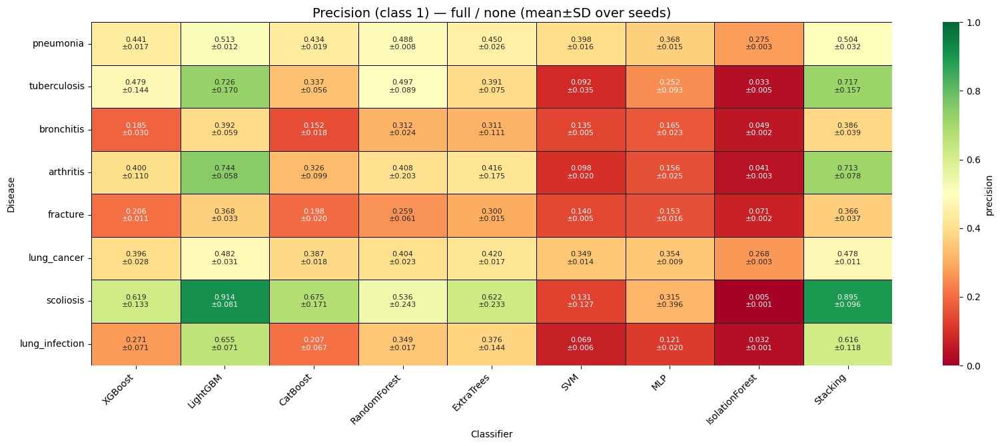

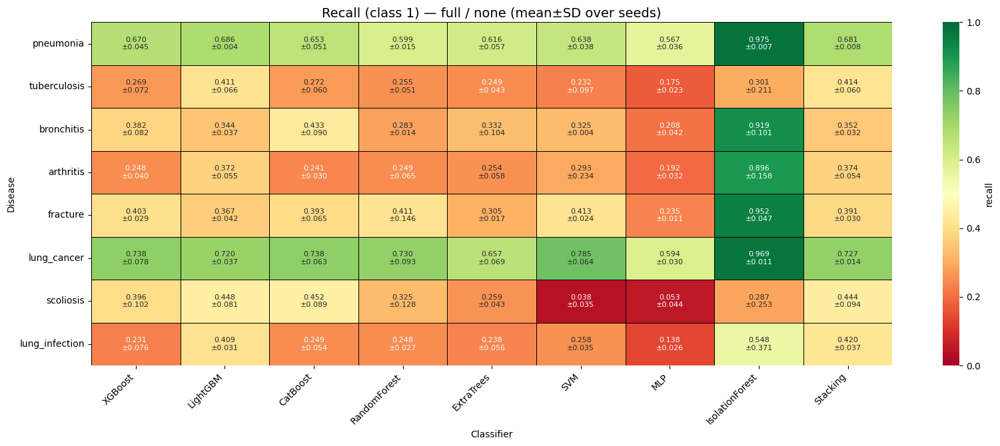

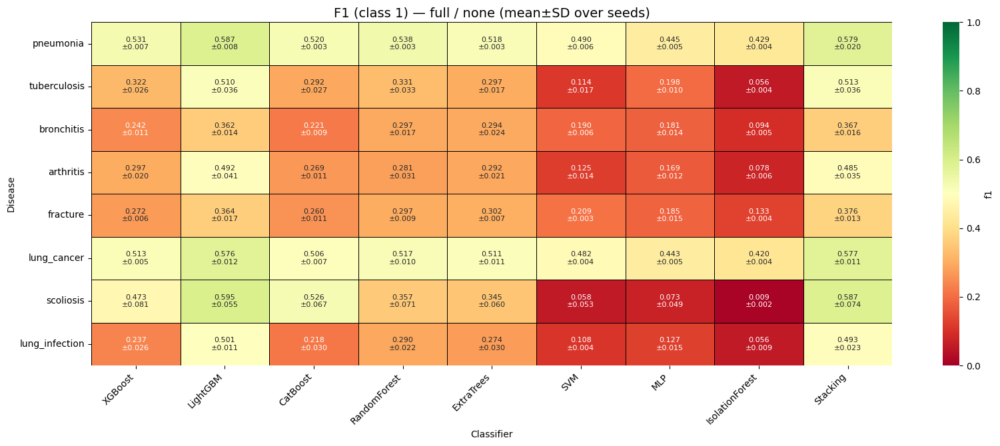

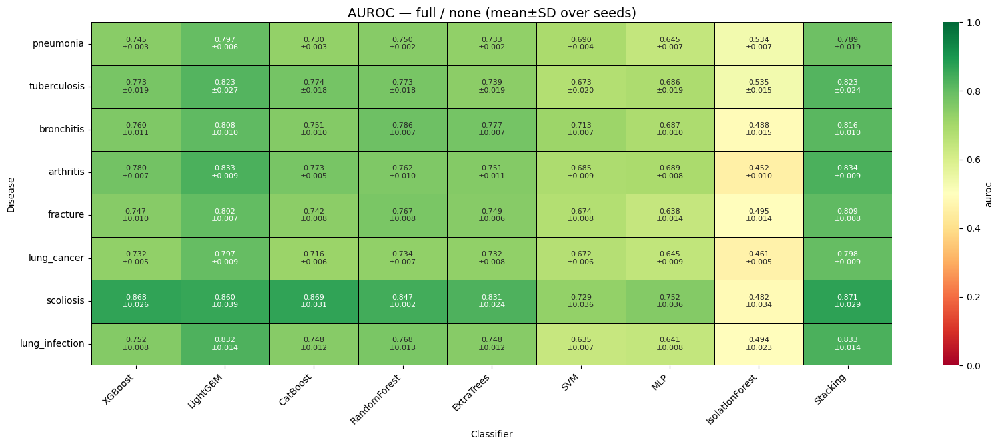

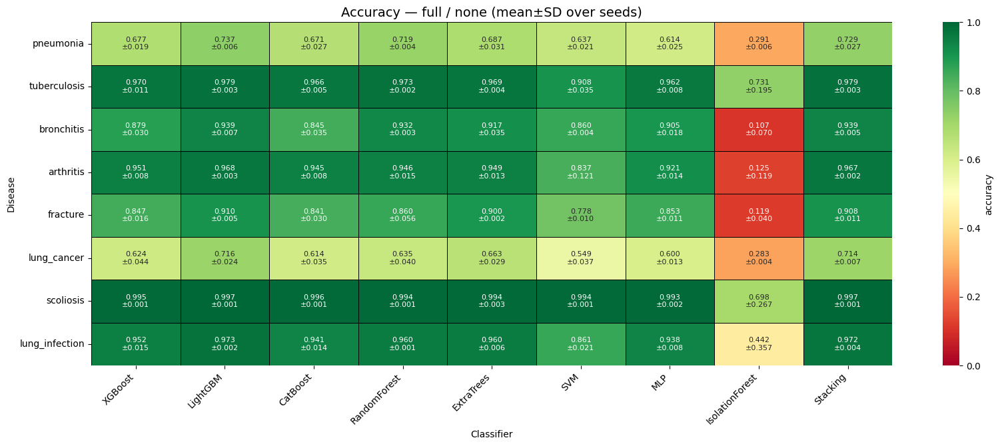

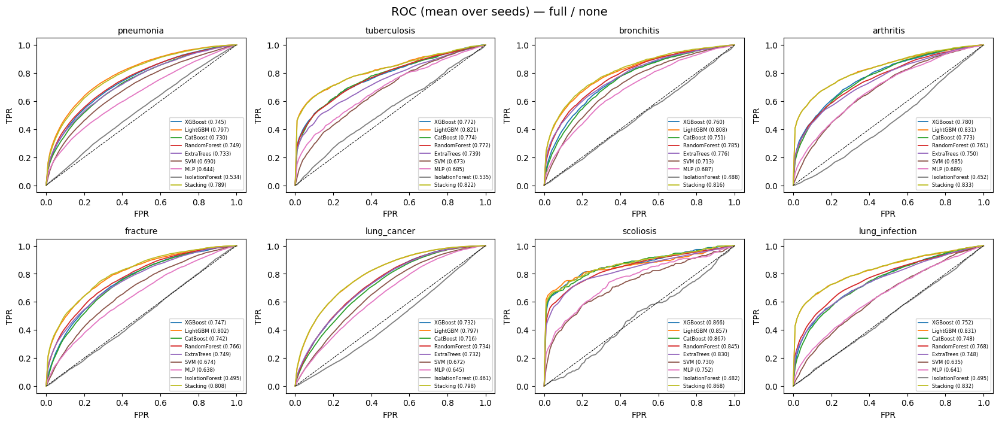

[kaggle ckpt] pushed -> tuanducngo/approach1-iterimp-ckpt (4032 rows)


full/smotenc: 100%|██████████| 8/8 [00:00<00:00, 26255.42it/s]


========== SCENARIO  arch=full  augmenter=smotenc ==========


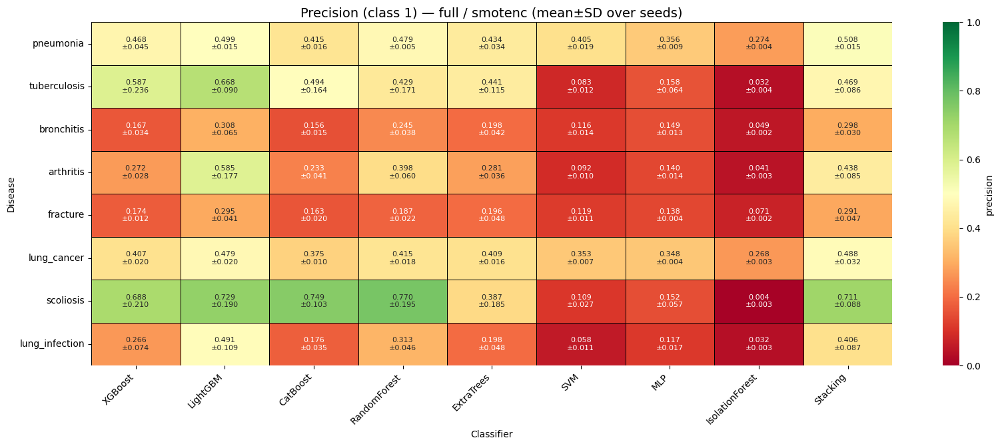

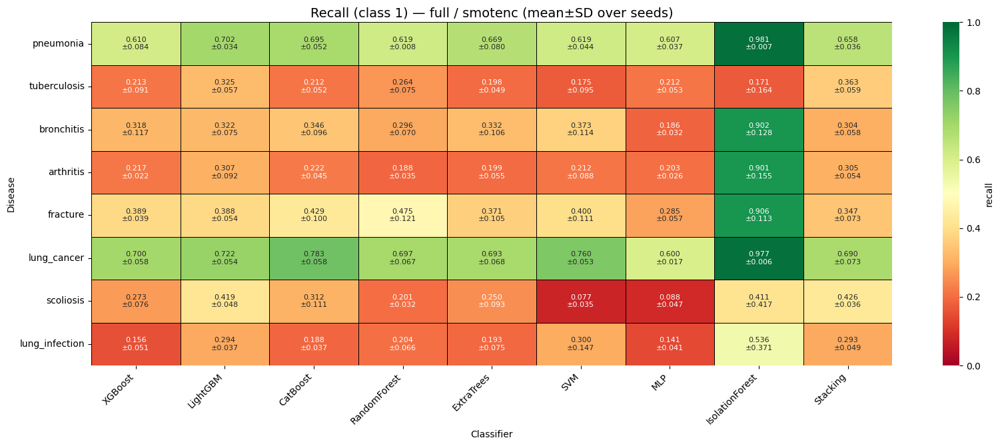

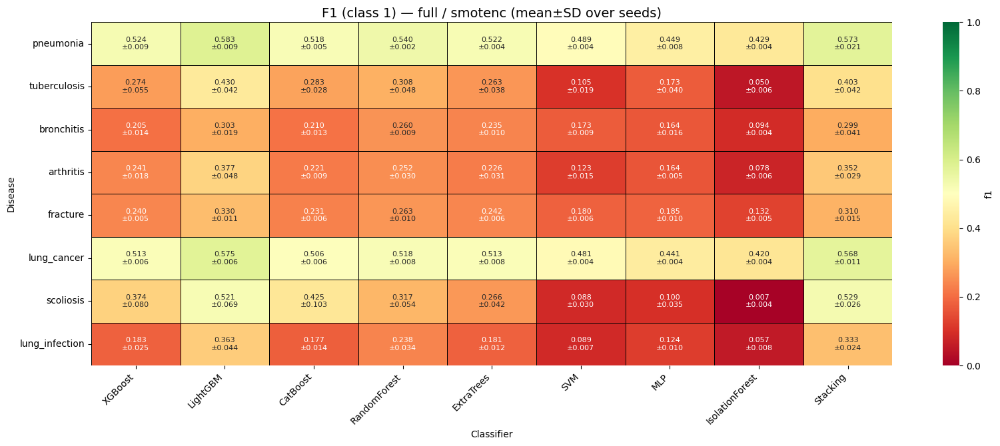

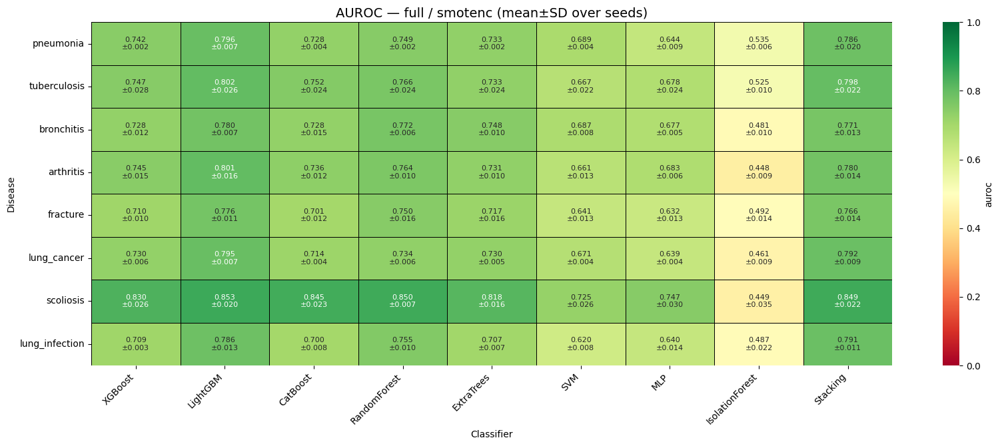

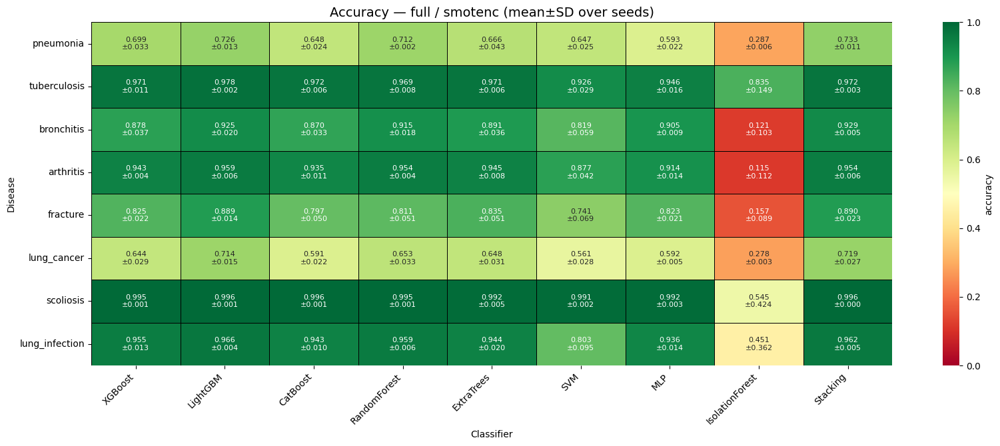

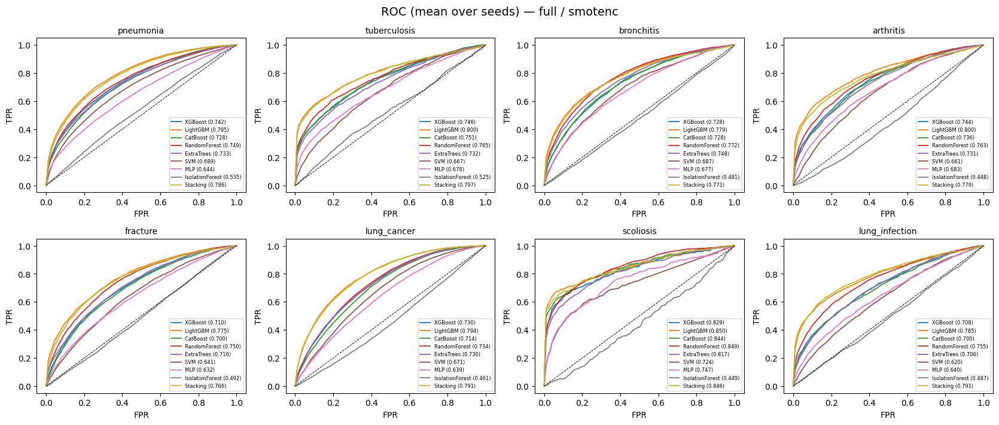

[kaggle ckpt] pushed -> tuanducngo/approach1-iterimp-ckpt (4032 rows)


full/gsmote: 100%|██████████| 8/8 [00:00<00:00, 31805.15it/s]


========== SCENARIO  arch=full  augmenter=gsmote ==========


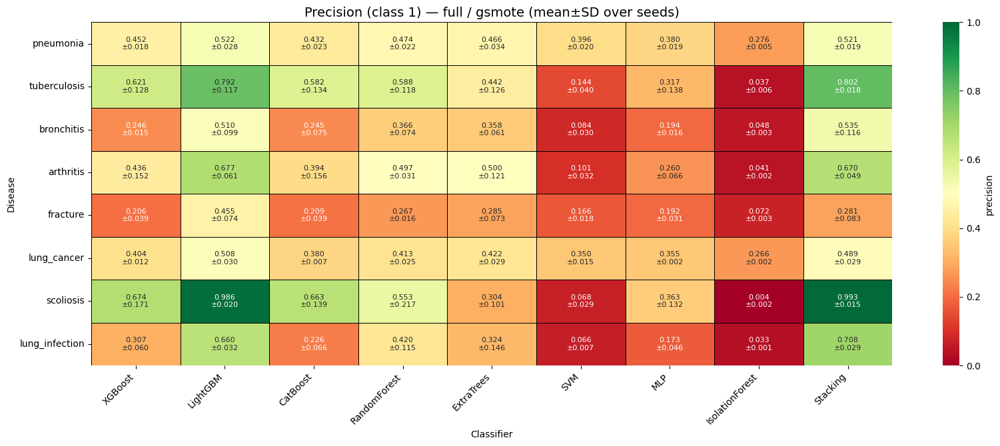

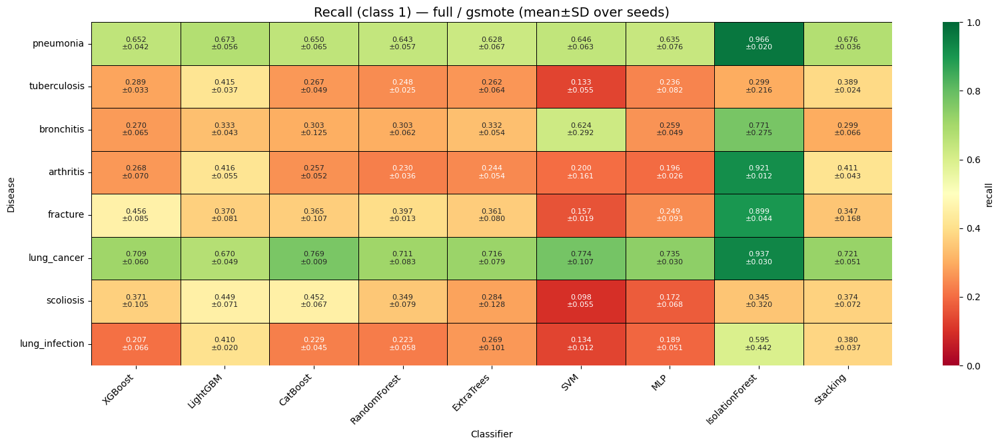

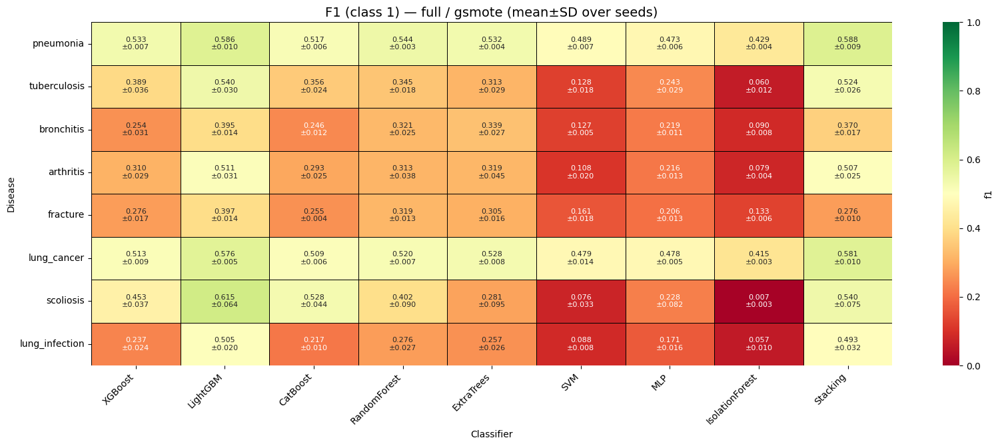

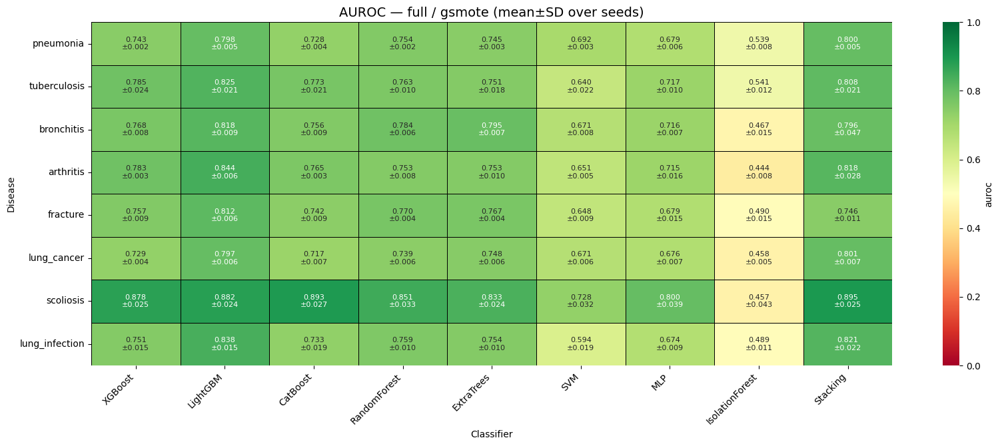

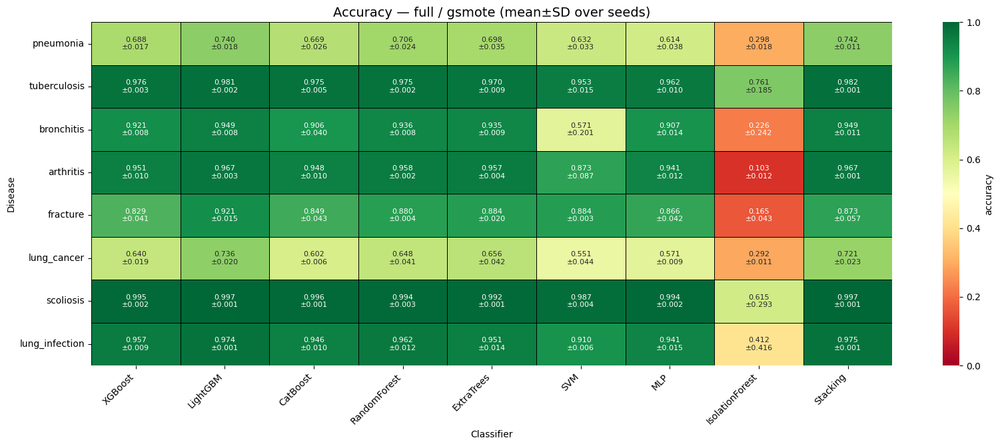

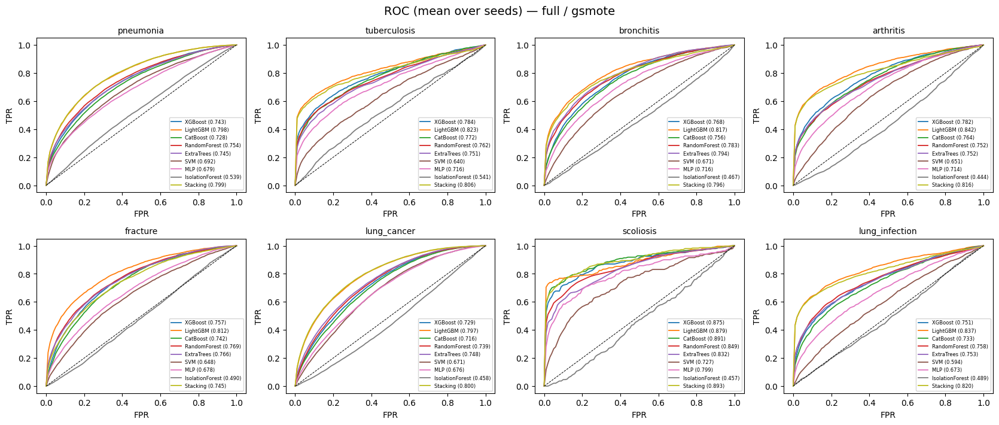

[kaggle ckpt] pushed -> tuanducngo/approach1-iterimp-ckpt (4032 rows)


full/adasyn: 100%|██████████| 8/8 [00:00<00:00, 23399.19it/s]


========== SCENARIO  arch=full  augmenter=adasyn ==========


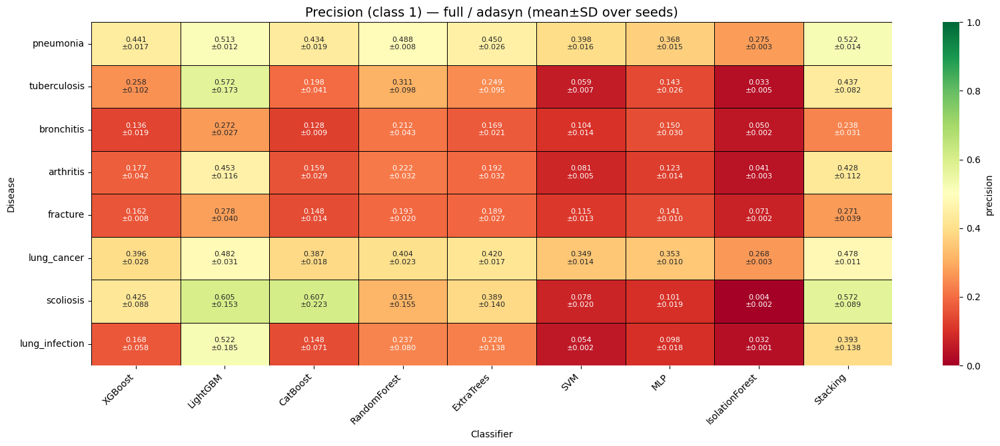

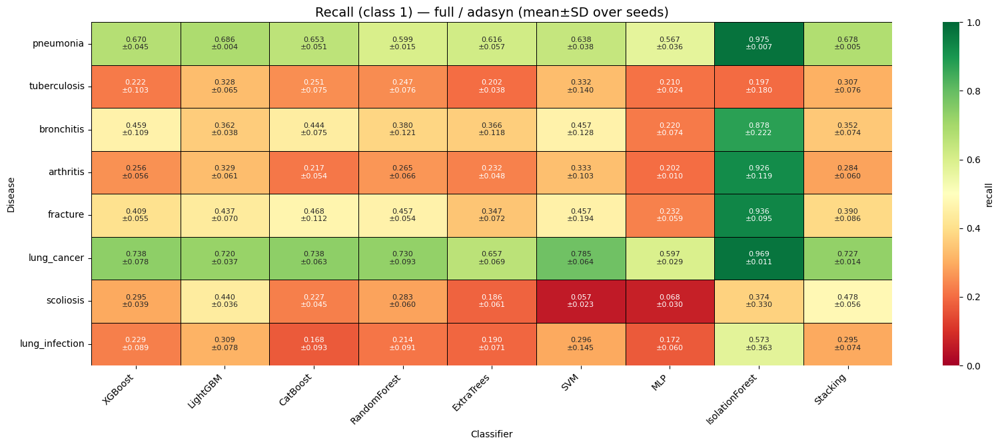

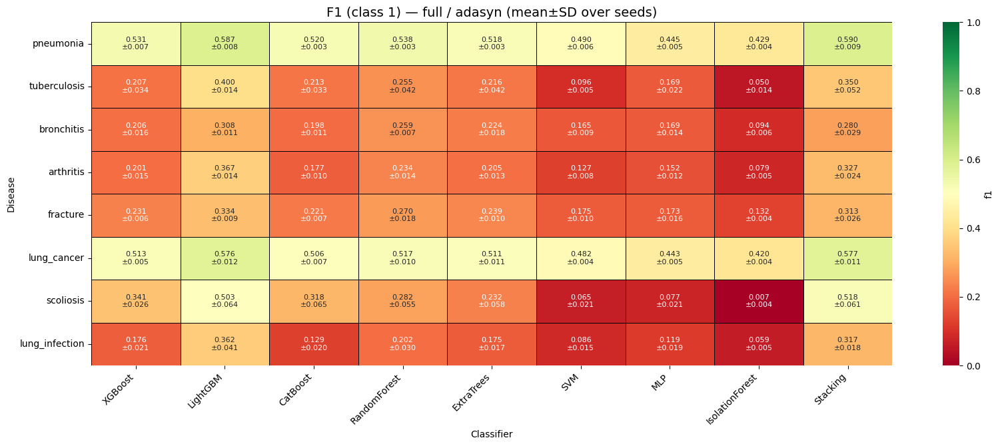

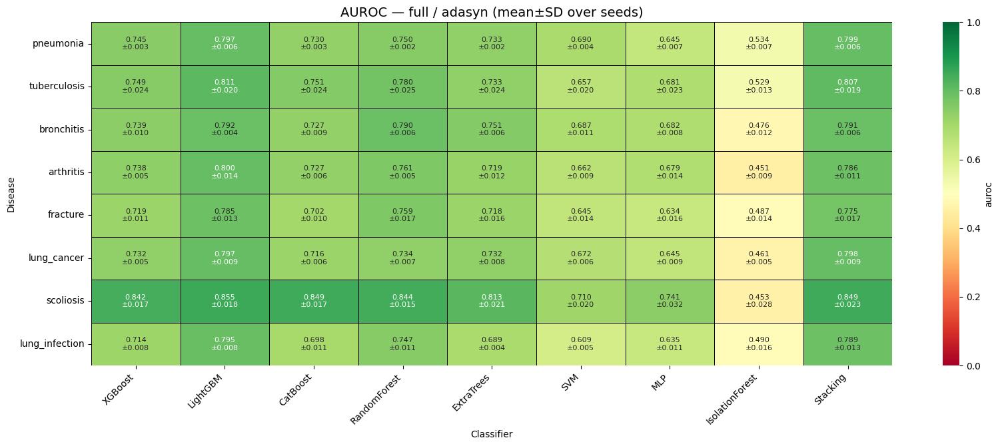

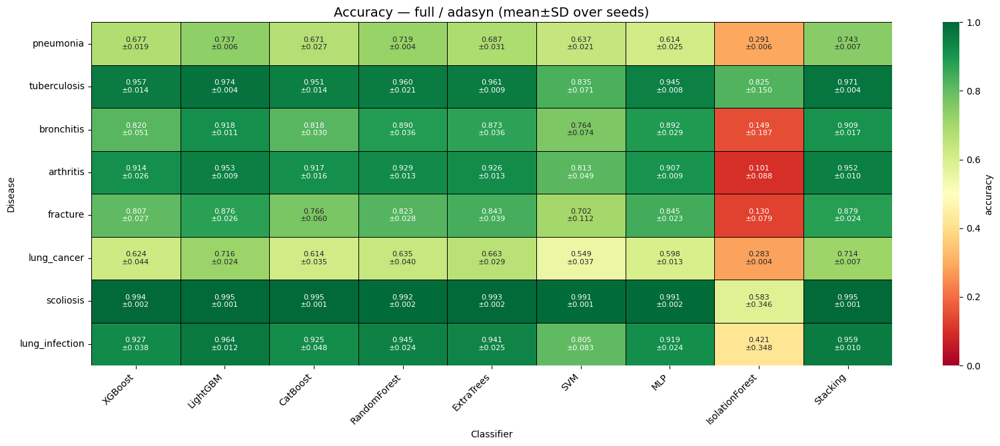

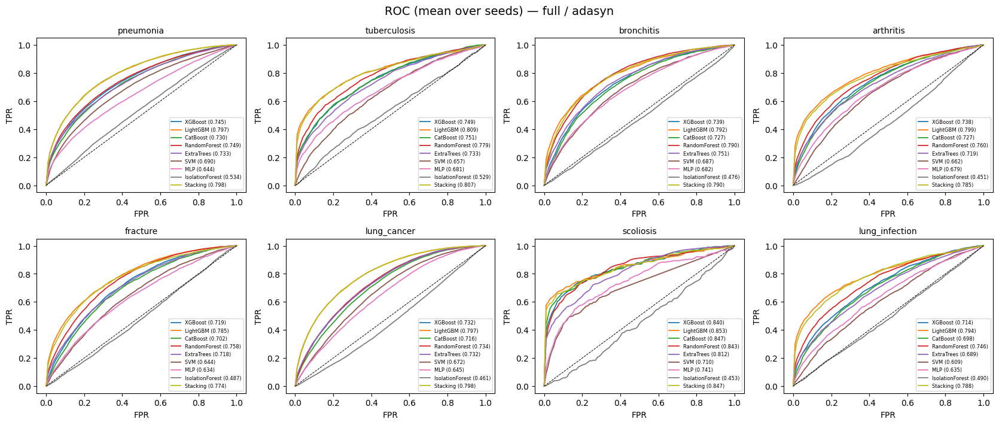

[kaggle ckpt] pushed -> tuanducngo/approach1-iterimp-ckpt (4032 rows)


full/svmsmote: 100%|██████████| 8/8 [00:00<00:00, 23497.50it/s]


========== SCENARIO  arch=full  augmenter=svmsmote ==========


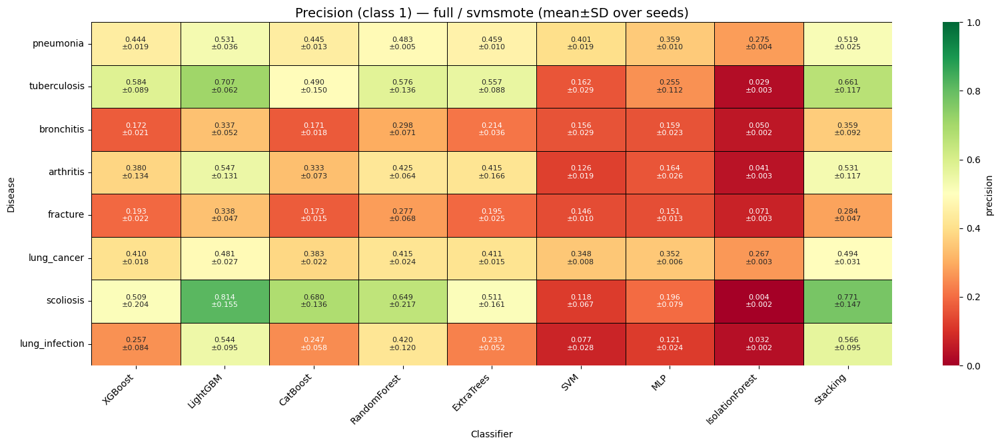

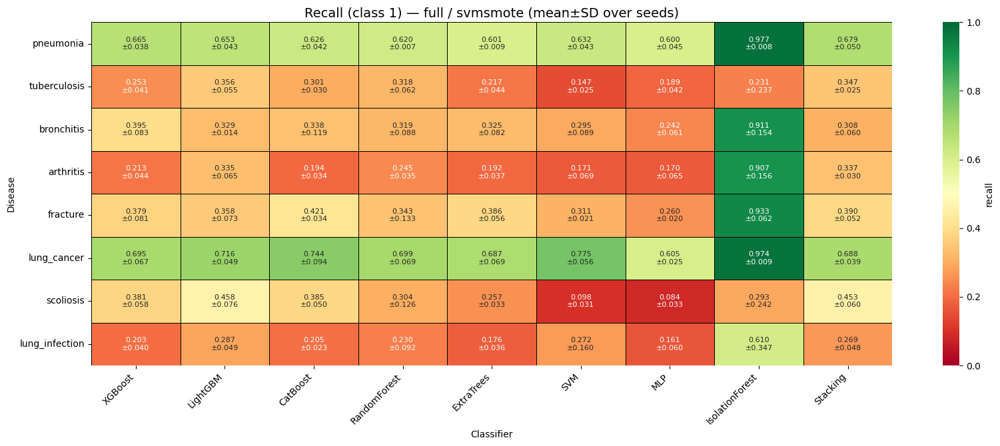

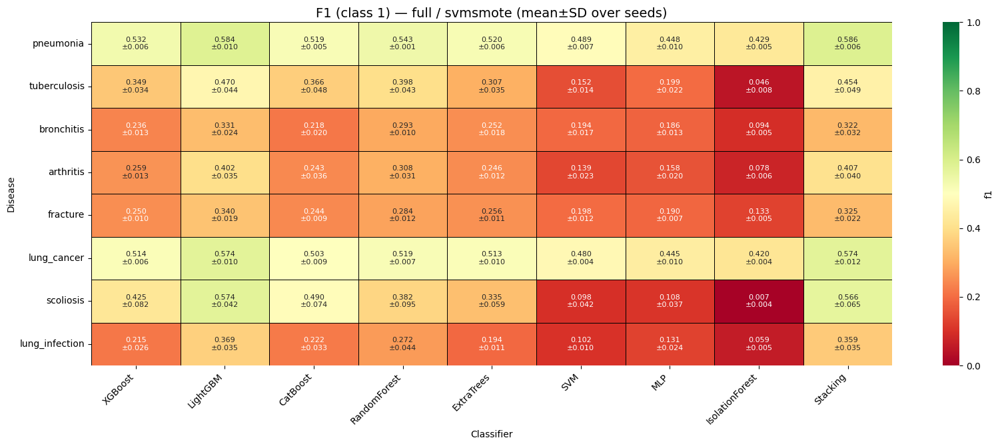

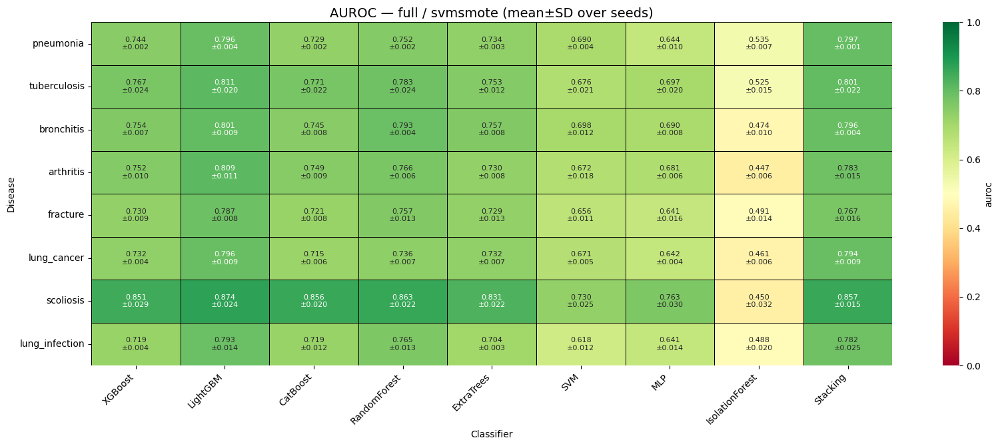

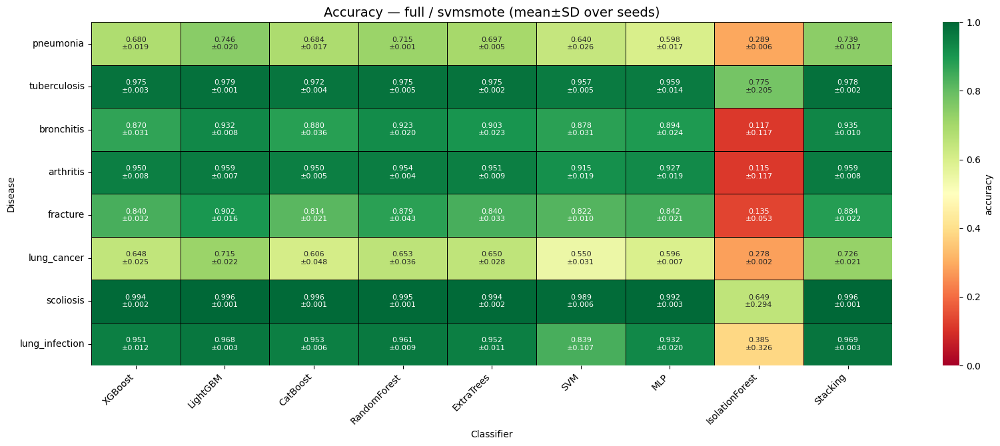

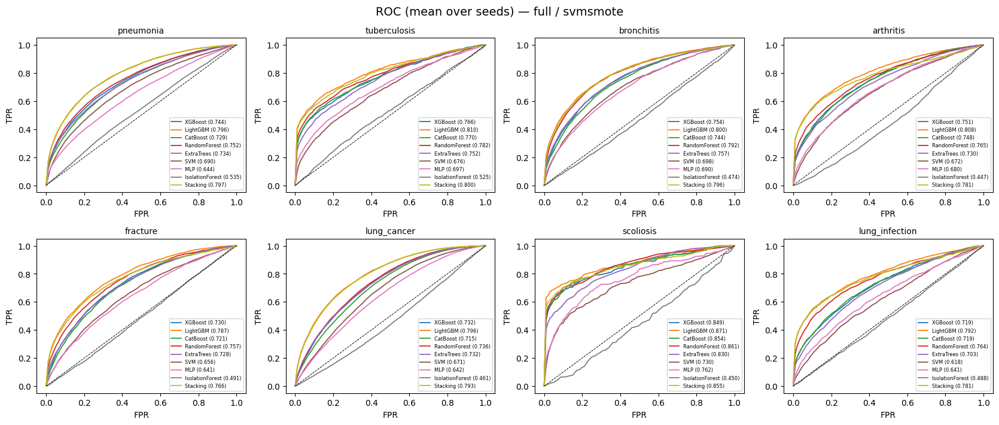

[kaggle ckpt] pushed -> tuanducngo/approach1-iterimp-ckpt (4032 rows)


full/borderlinesmote: 100%|██████████| 8/8 [00:00<00:00, 25209.94it/s]


========== SCENARIO  arch=full  augmenter=borderlinesmote ==========


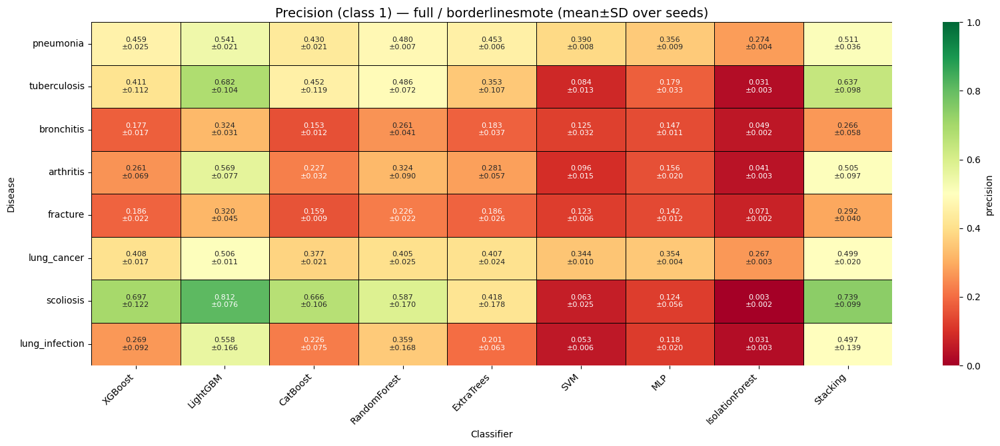

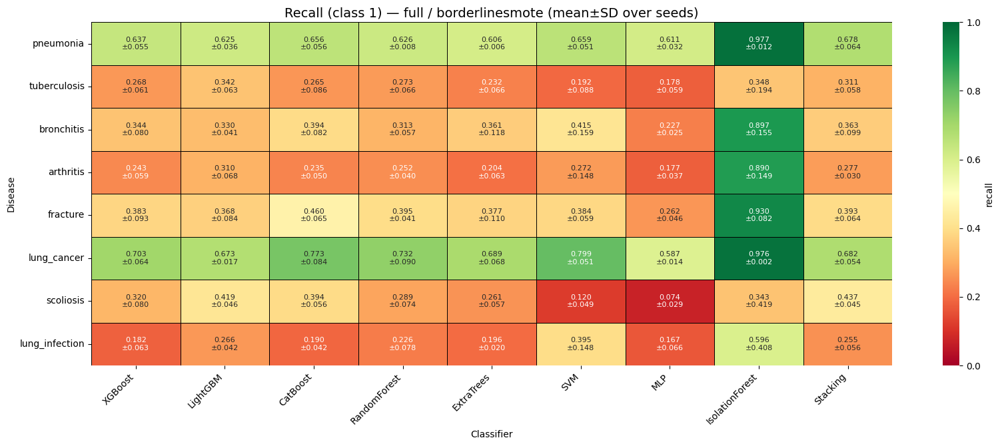

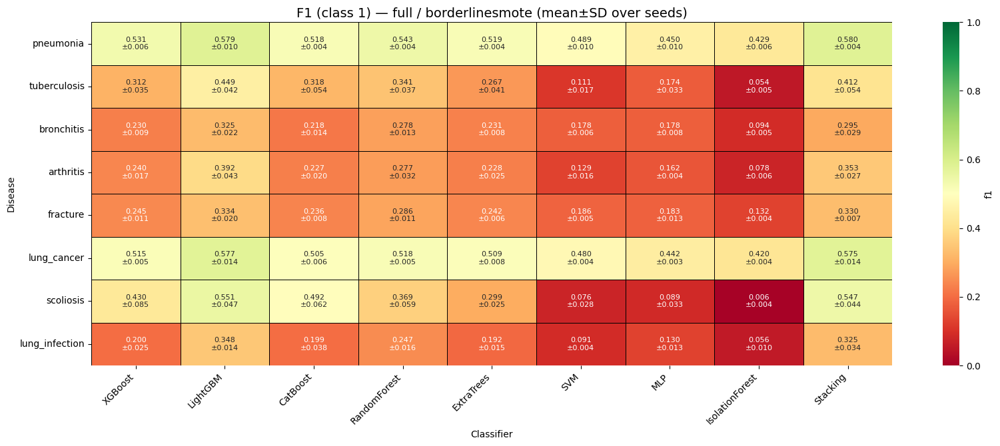

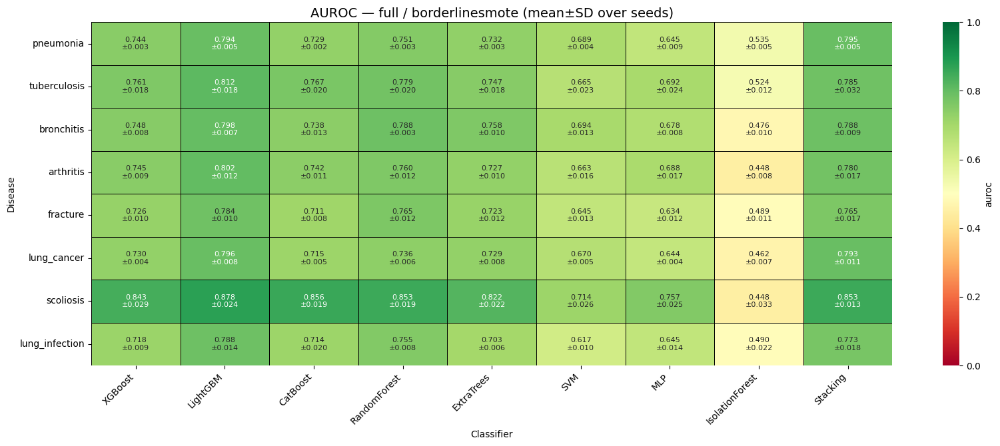

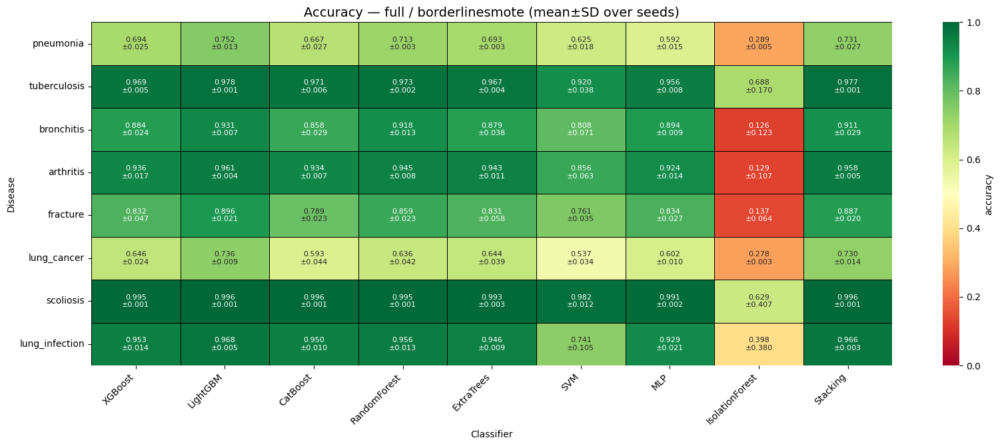

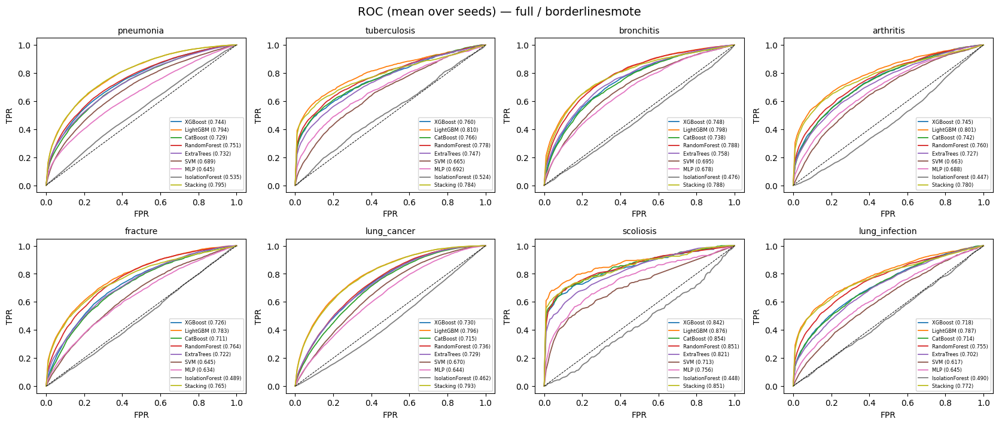

[kaggle ckpt] pushed -> tuanducngo/approach1-iterimp-ckpt (4032 rows)


full/kmeanssmote: 100%|██████████| 8/8 [00:00<00:00, 26092.09it/s]


========== SCENARIO  arch=full  augmenter=kmeanssmote ==========


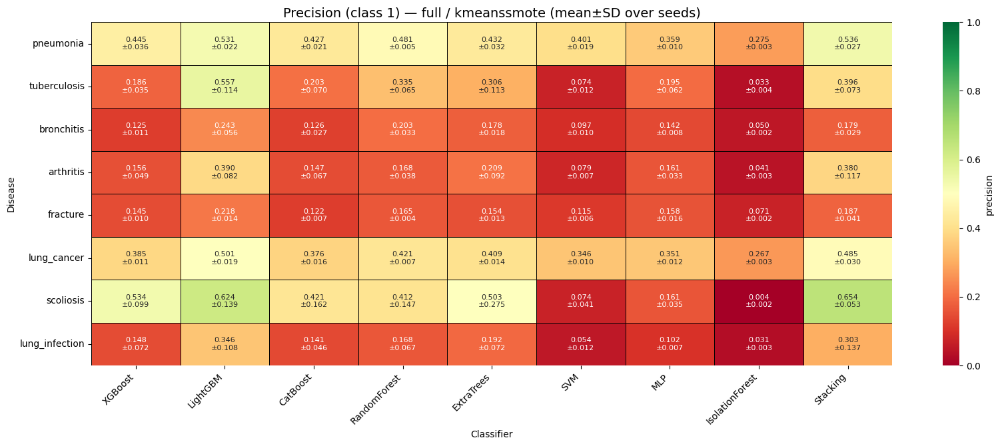

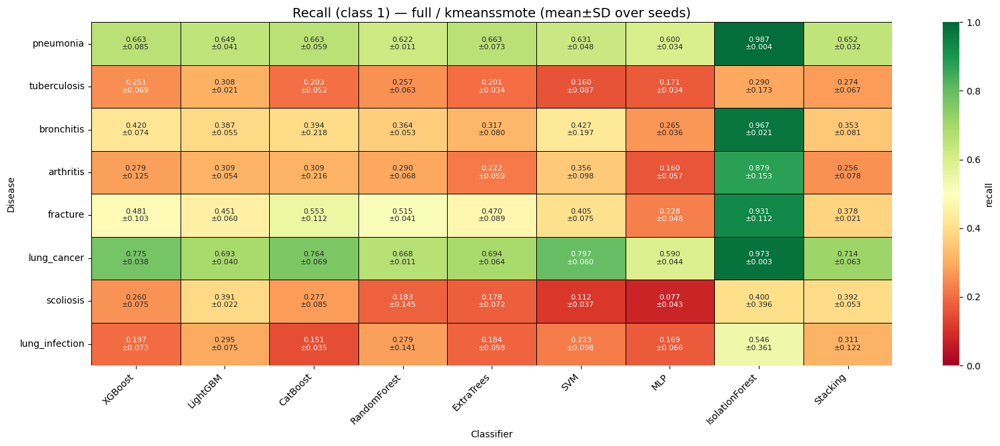

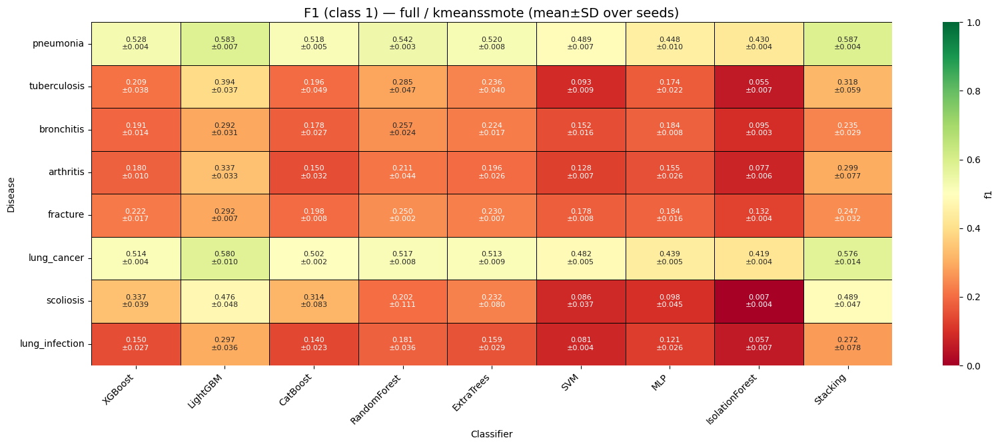

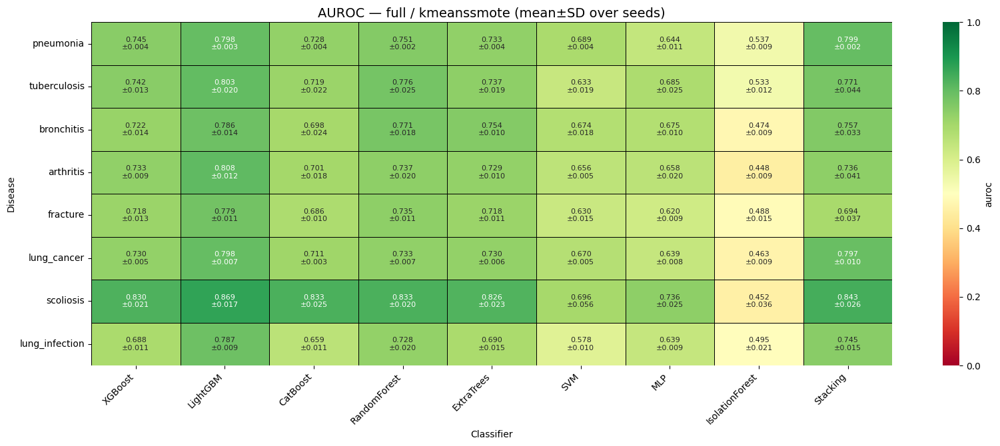

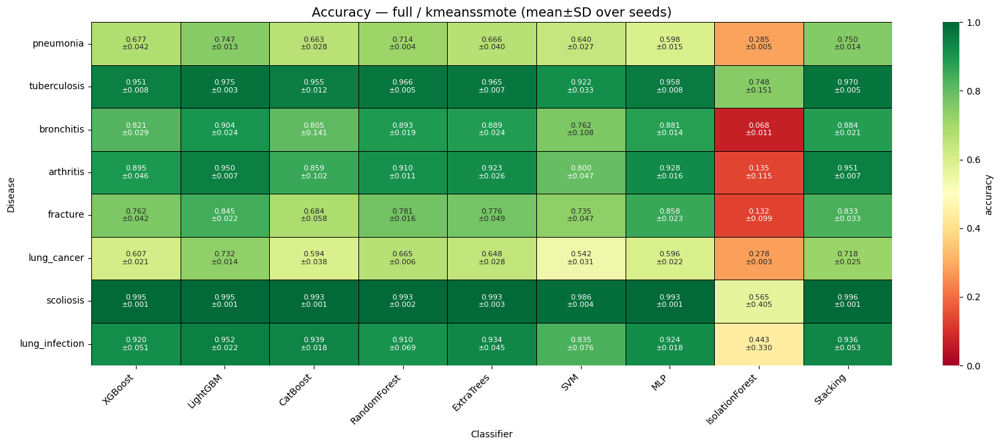

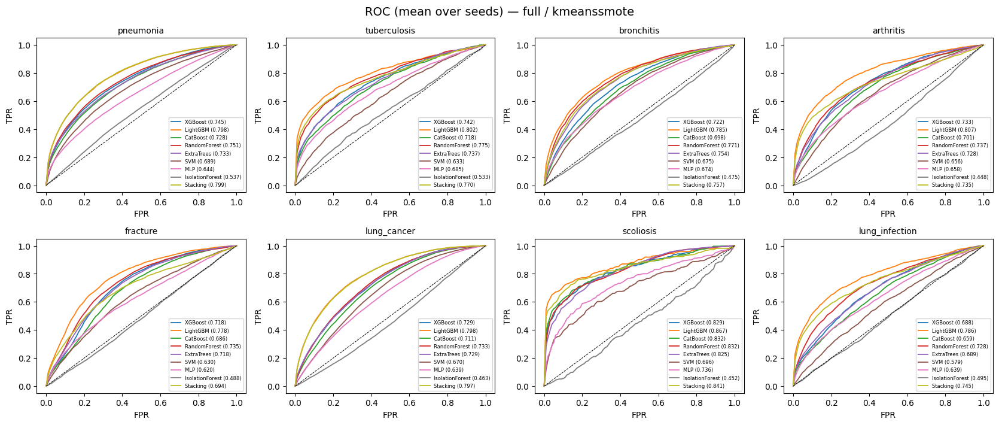

[kaggle ckpt] pushed -> tuanducngo/approach1-iterimp-ckpt (4032 rows)


full/ctgan: 100%|██████████| 8/8 [00:00<00:00, 24929.00it/s]


========== SCENARIO  arch=full  augmenter=ctgan ==========


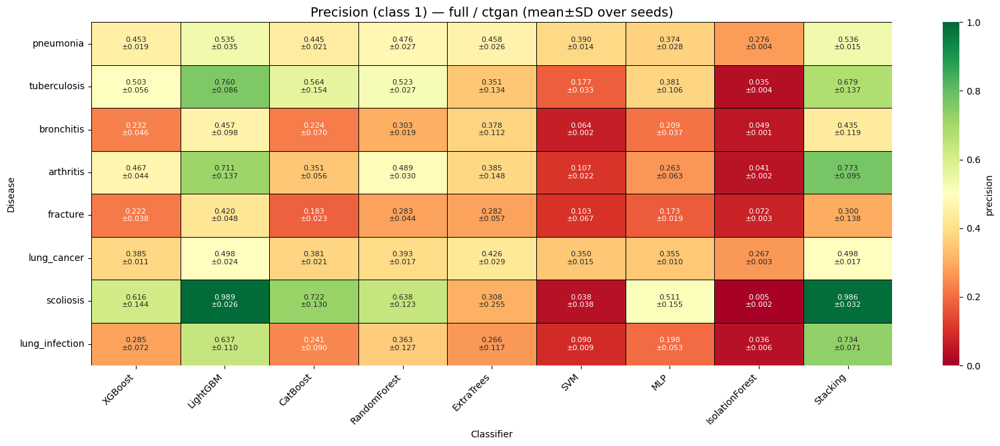

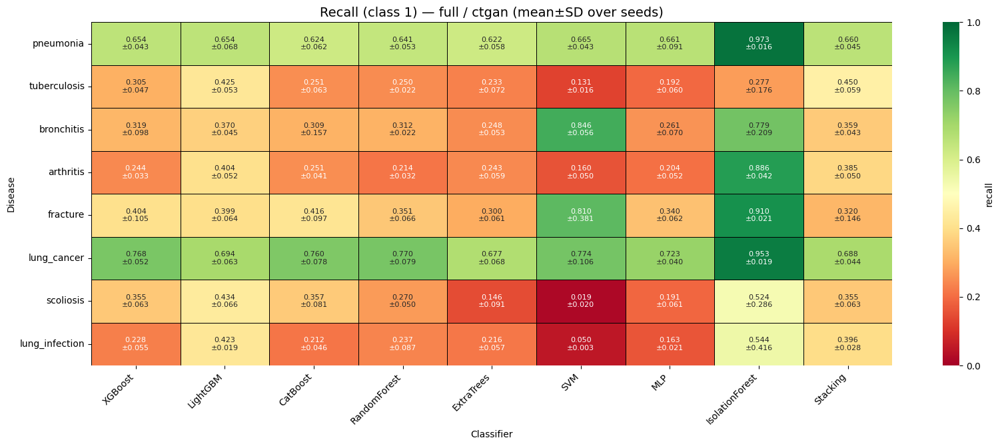

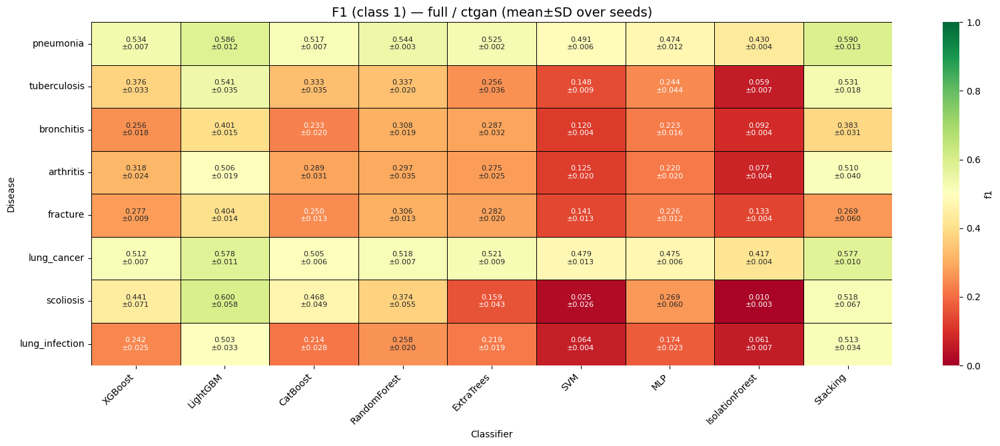

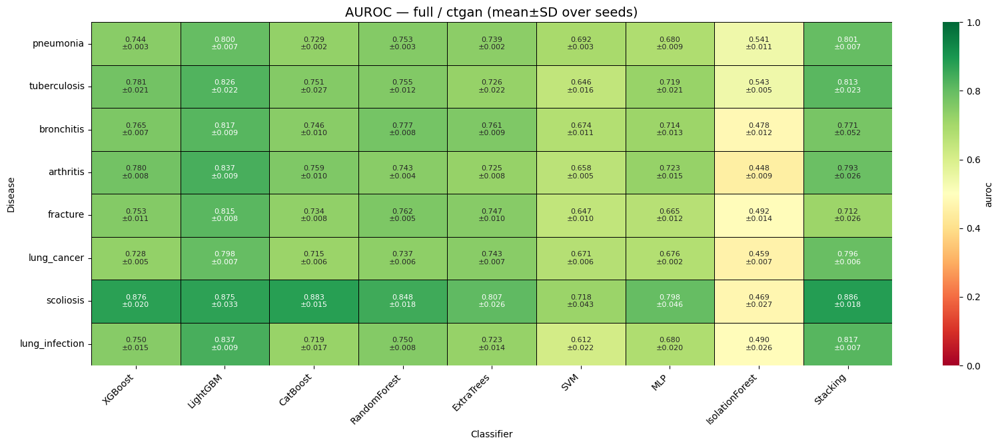

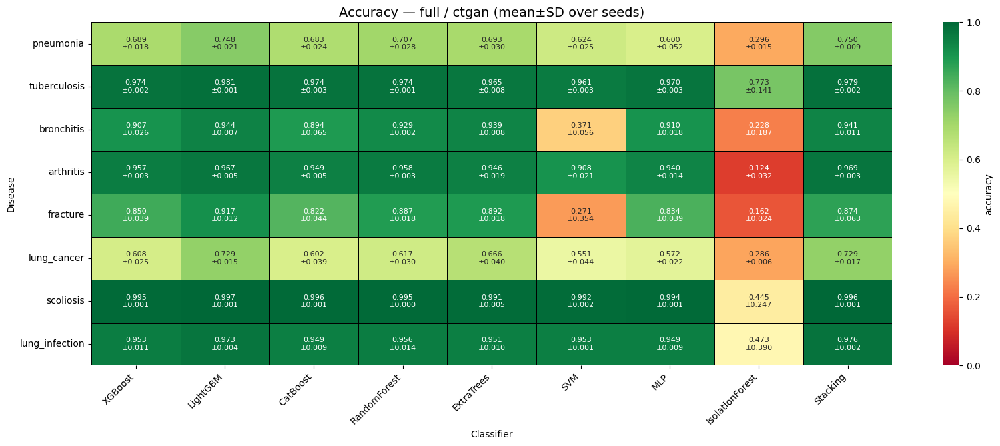

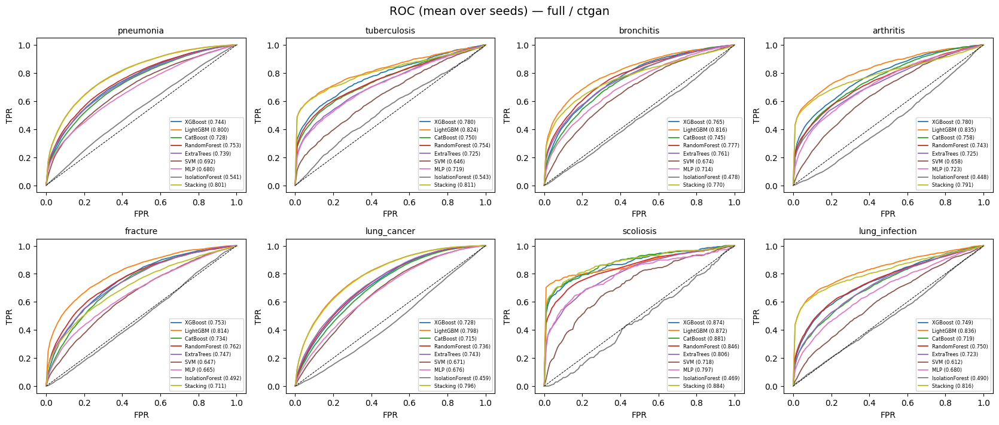

[kaggle ckpt] pushed -> tuanducngo/approach1-iterimp-ckpt (4032 rows)


imgrec/none: 100%|██████████| 8/8 [00:00<00:00, 32017.59it/s]


========== SCENARIO  arch=imgrec  augmenter=none ==========


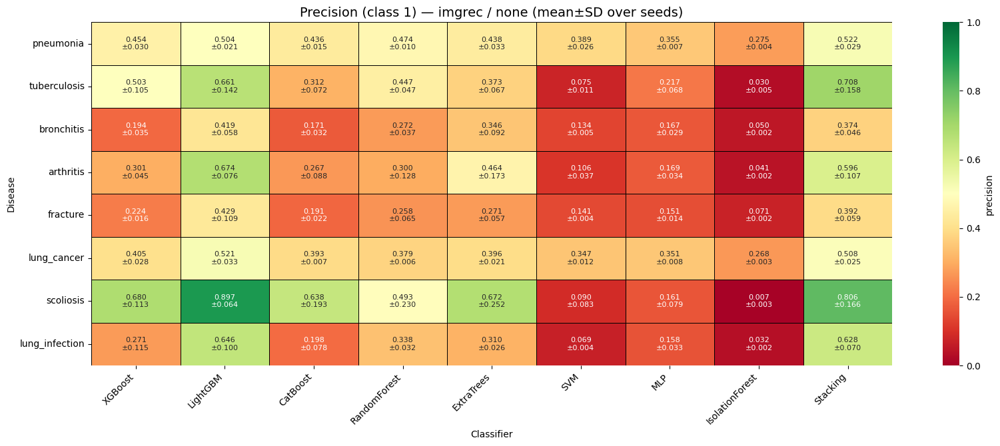

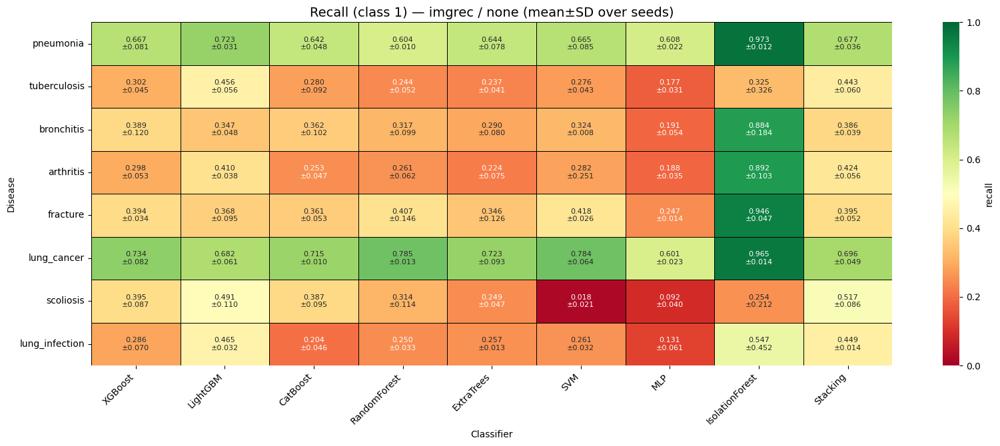

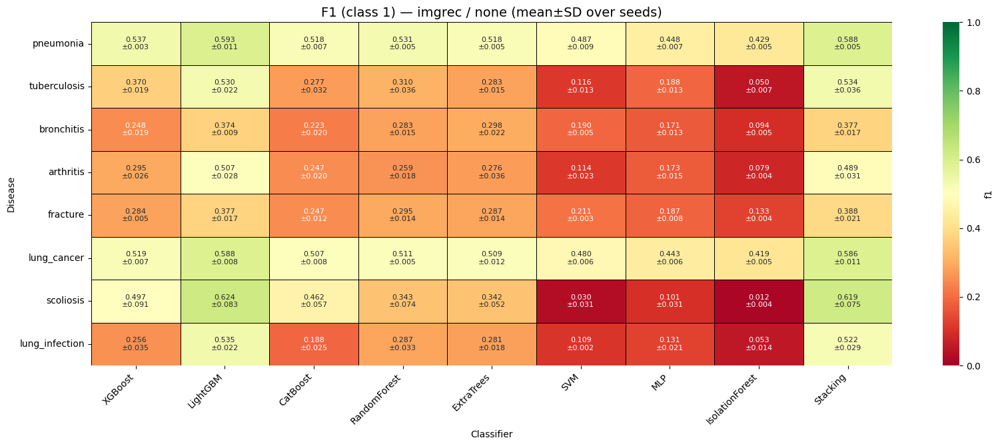

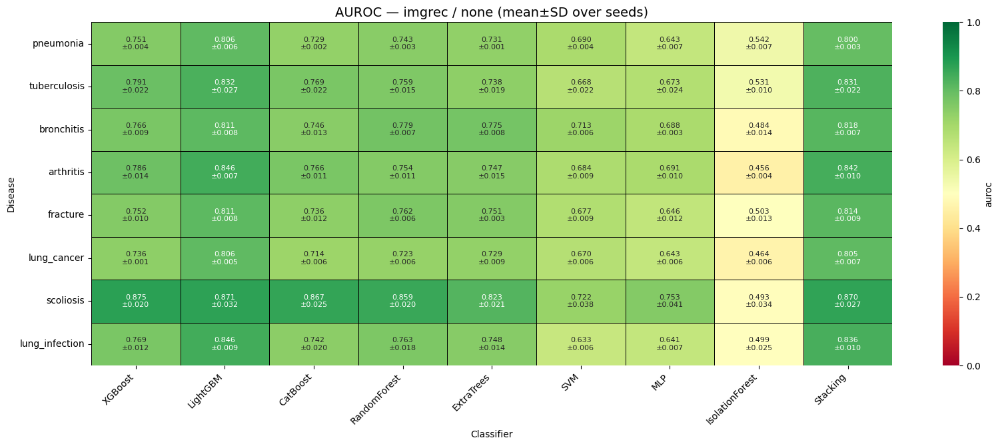

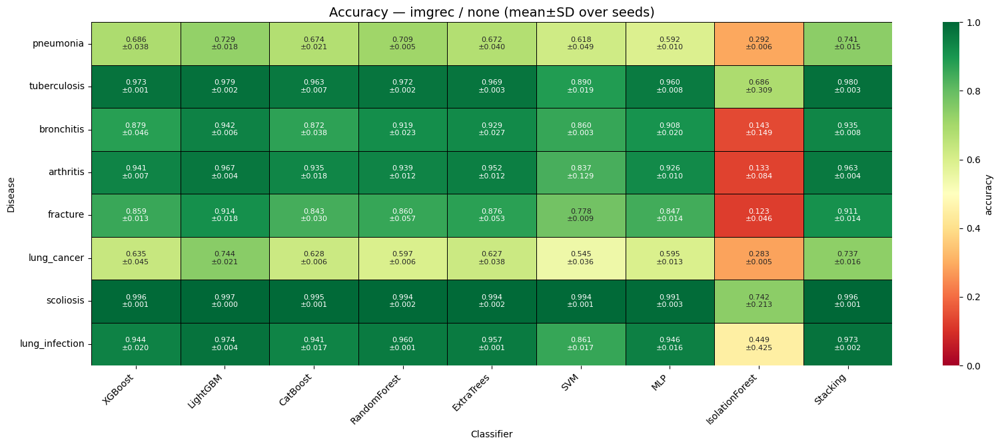

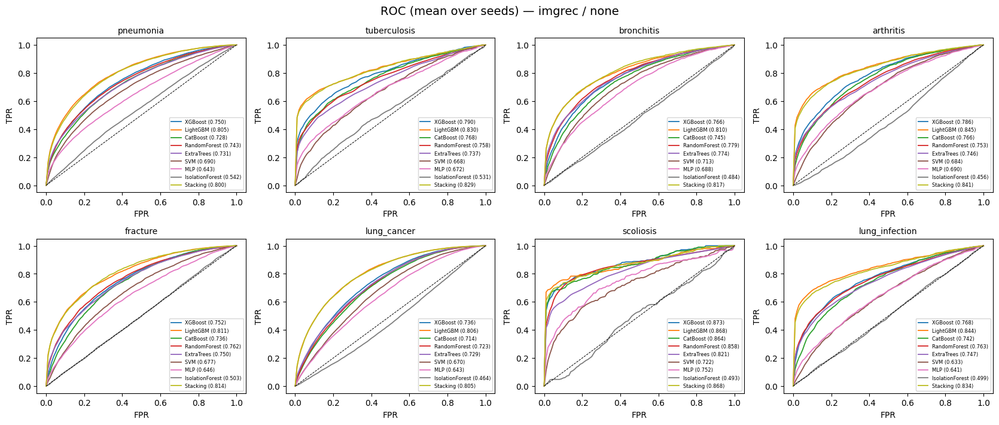

[kaggle ckpt] pushed -> tuanducngo/approach1-iterimp-ckpt (4032 rows)


imgrec/smotenc: 100%|██████████| 8/8 [00:00<00:00, 32232.88it/s]


========== SCENARIO  arch=imgrec  augmenter=smotenc ==========


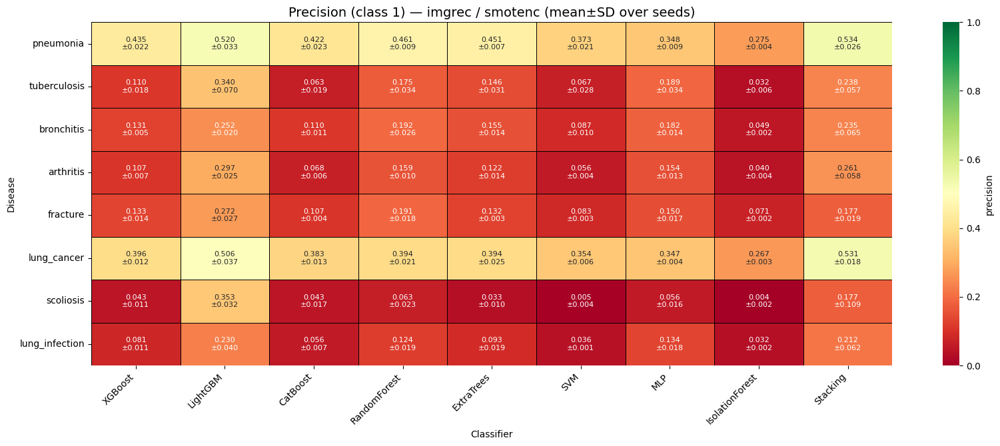

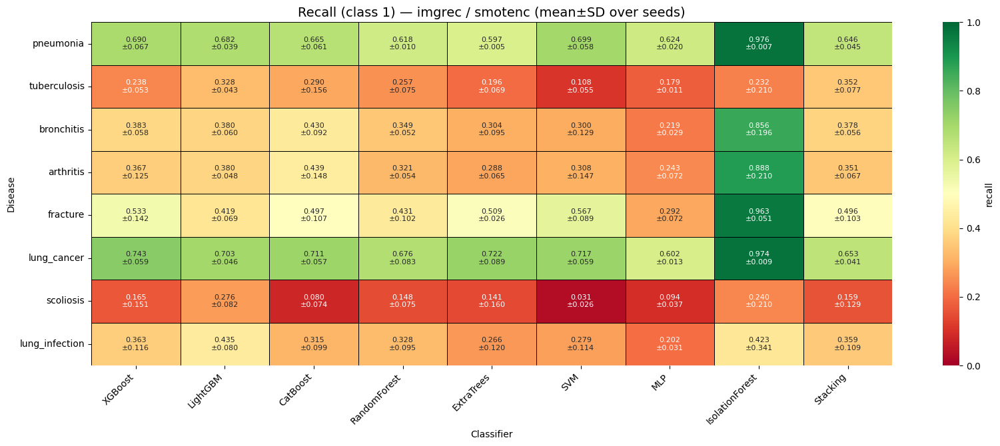

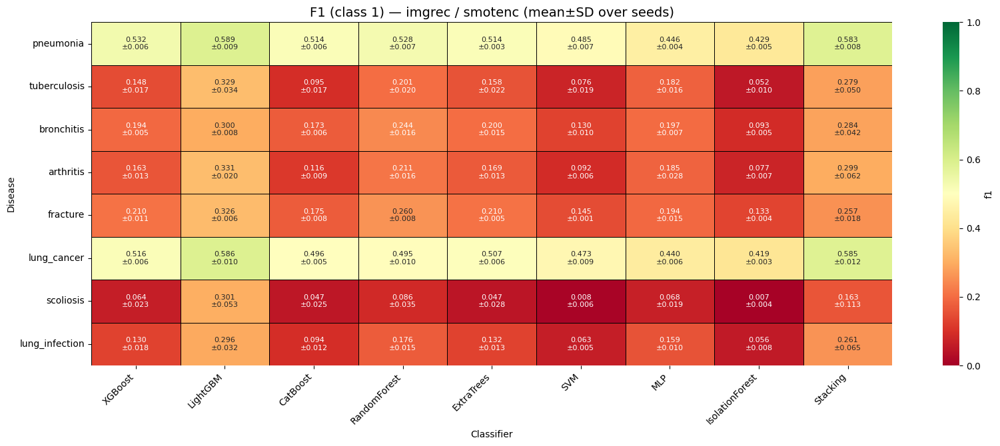

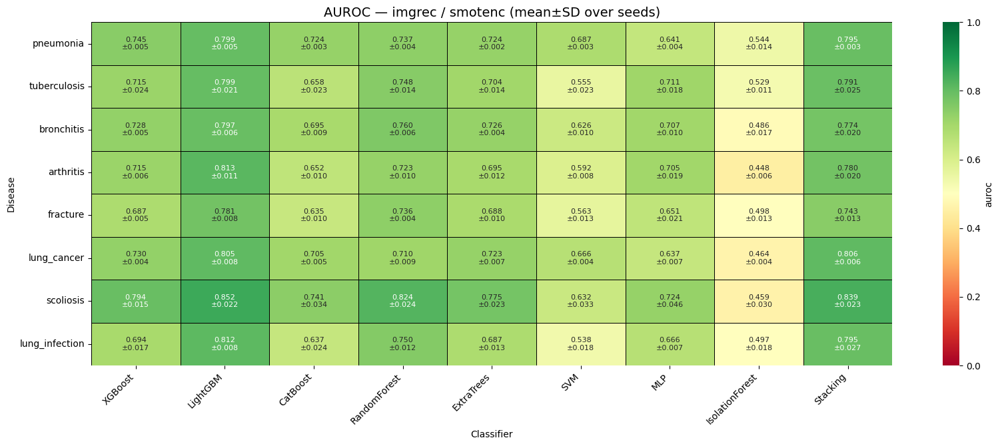

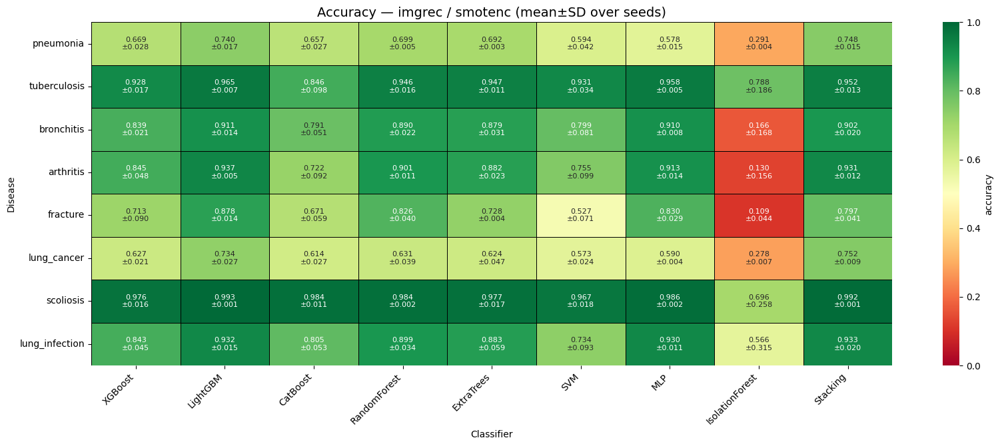

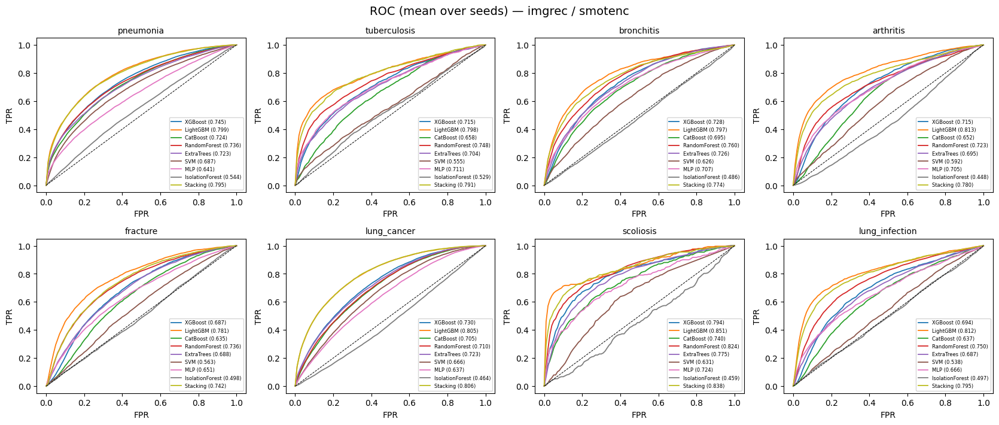

[kaggle ckpt] pushed -> tuanducngo/approach1-iterimp-ckpt (4032 rows)


imgrec/gsmote: 100%|██████████| 8/8 [00:00<00:00, 30504.03it/s]


========== SCENARIO  arch=imgrec  augmenter=gsmote ==========


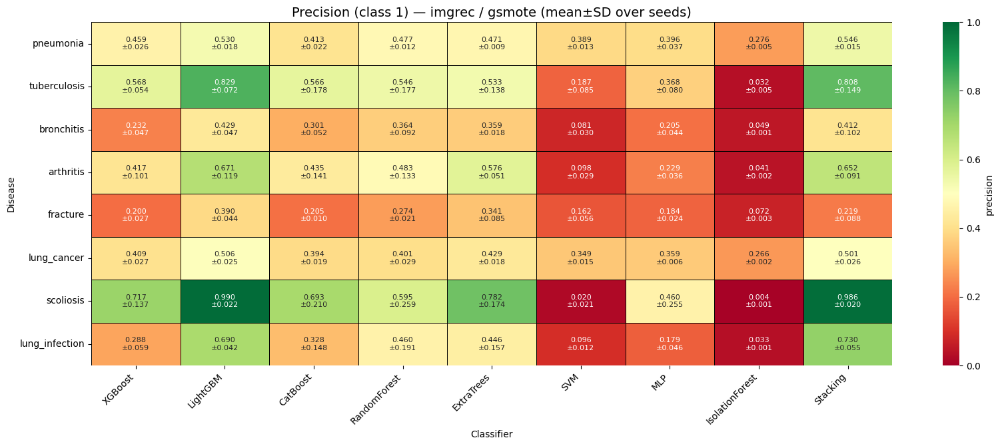

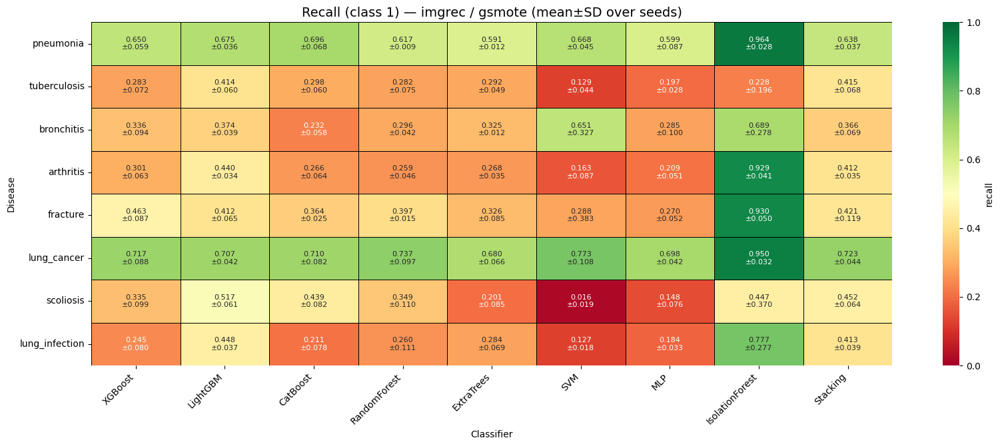

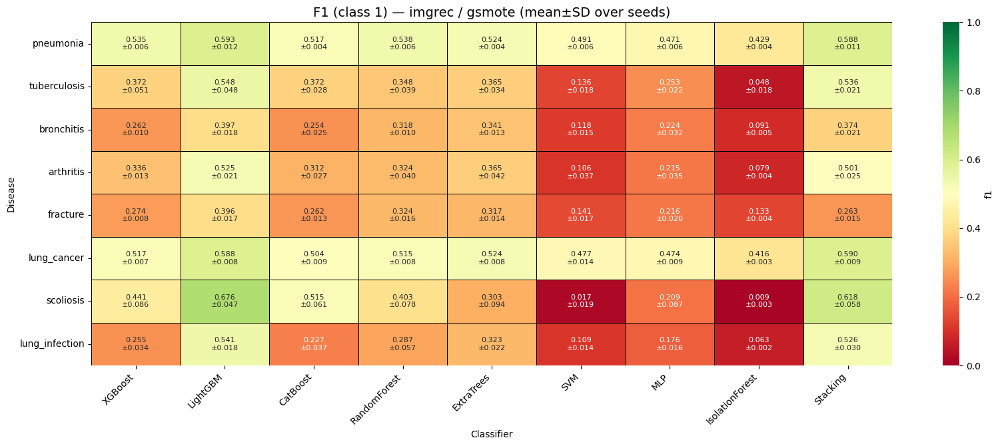

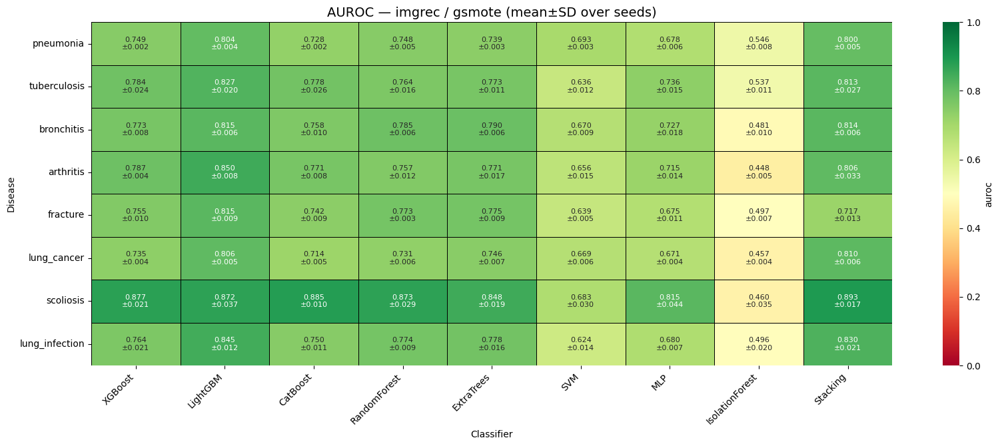

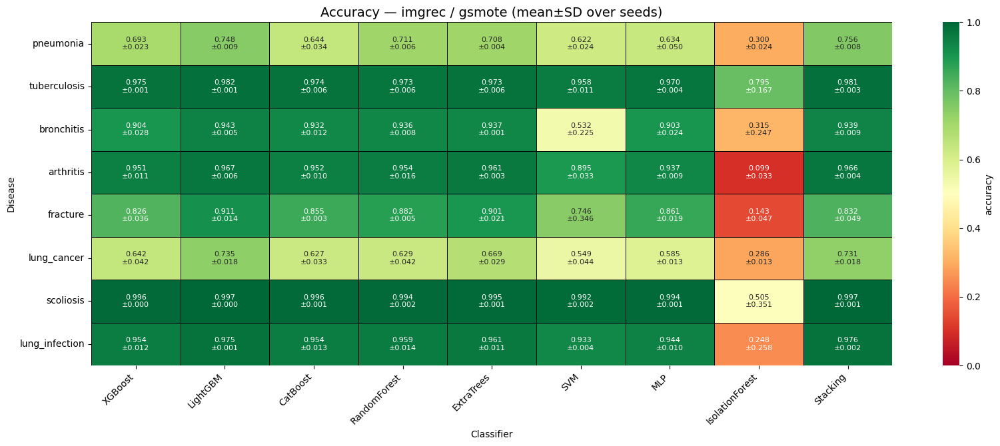

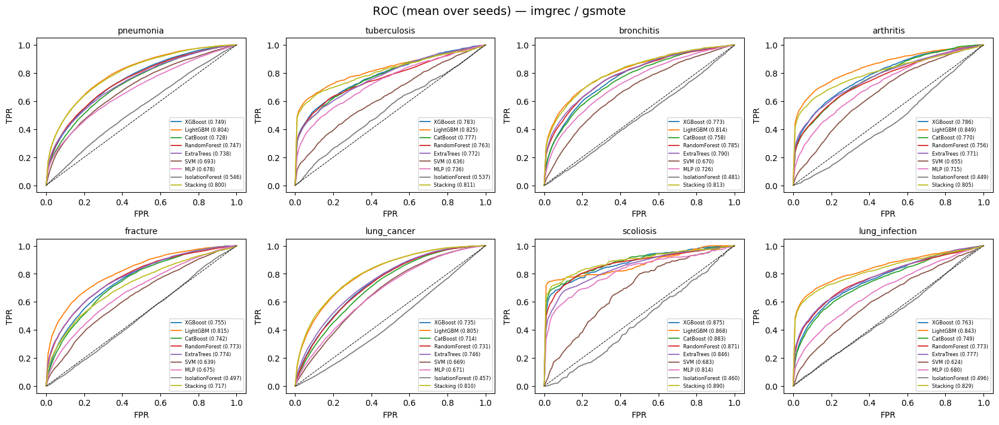

[kaggle ckpt] pushed -> tuanducngo/approach1-iterimp-ckpt (4032 rows)


imgrec/adasyn:  12%|█▎        | 1/8 [00:13<01:35, 13.69s/it]


KeyboardInterrupt: 

In [21]:
# === Main loop (resume-safe). Scenario = (arch, augmenter). ===
# --- Config knobs ---
QUICK = False       # True = smoke test; set False for the full run
CW    = True       # class-weight ON (approach 1)

if QUICK:
    RUN_ARCHS      = ['full']
    RUN_AUGMENTERS = ['none', 'smotenc', 'gsmote', 'adasyn']
    RUN_DISEASES   = ['pneumonia']
    RUN_SEEDS      = [42]
    RUN_CLASSIFIERS = ['XGBoost', 'RandomForest', 'MLP', 'IsolationForest', 'Stacking']
    RUN_CLASSIFIERS = [c for c in RUN_CLASSIFIERS if c == 'Stacking' or c in CLF_REGISTRY]
else:
    RUN_ARCHS      = ['full', 'imgrec']
    RUN_AUGMENTERS = [
        'none',
        'smotenc',
        'gsmote',
        'adasyn',
        'svmsmote',
        'borderlinesmote',
        'kmeanssmote',
        'ctgan',
        # 'ctabganplus',   # tạm bỏ qua CTAB-GAN+ (nặng) — bỏ dấu # để bật lại
    ]           # none + 6 smote-like + ctgan + ctabganplus
    RUN_DISEASES   = diseases
    RUN_SEEDS      = [42, 43, 44, 45, 46]           # 5 seeds
    RUN_CLASSIFIERS = DEFAULT_CLASSIFIERS

if IN_KAGGLE and KAGGLE_CKPT:
    restore_checkpoint()                # kéo checkpoint cũ từ Kaggle Dataset về trước khi chạy
results = load_results()
roc     = load_roc()
done    = done_rows(results)
print('resuming with', len(results), 'rows;', len(done), 'classifier-rows done')

def _mk_row(disease, arch, aug, name, seed, ratio, m):
    return {'Disease': disease, 'arch': arch, 'augmenter': aug, 'Model': name, 'seed': seed,
            'aug_ratio': ratio, 'threshold': m['thr'], 'precision': m['precision'],
            'recall': m['recall'], 'f1': m['f1'], 'accuracy': m['accuracy'], 'auroc': m['auroc'],
            'val_f1': m.get('val_f1', float('nan')), 'stack_members': m.get('stack_members', '')}

def _save_row(disease, arch, aug, name, seed, ratio, m):
    """Append one classifier row and CHECKPOINT immediately (CSV + ROC)."""
    global results
    roc[(disease, arch, aug, name, seed)] = {'fpr': m['fpr'], 'tpr': m['tpr']}
    results = pd.concat([results, pd.DataFrame([_mk_row(disease, arch, aug, name, seed, ratio, m)])],
                        ignore_index=True)
    done.add((disease, arch, aug, name, seed))
    save_results(results); save_roc(roc)

def run_block(disease, arch, aug, seed):
    base_clfs  = [c for c in RUN_CLASSIFIERS if c != 'Stacking']
    want_stack = 'Stacking' in RUN_CLASSIFIERS
    todo       = [c for c in base_clfs if (disease, arch, aug, c, seed) not in done]
    stack_left = want_stack and (disease, arch, aug, 'Stacking', seed) not in done
    if not todo and not stack_left:
        return                                          # cả block đã xong
    if arch == 'full':
        tr, te, va, xtr_imp, Xte, Xva = get_imputed(seed); xtr_raw = None
    else:
        tr, te, va, xtr_raw, Xte, Xva = get_split(seed); xtr_imp = None
    ytr, yte, yva = _labels3(disease, tr, te, va)
    Xa, ya, ratio = build_aug(disease, arch, aug, seed, xtr_imp, xtr_raw, ytr)

    # val F1 of base learners (để Stacking xếp hạng); nạp lại của cái đã xong từ trước
    val_f1 = {}
    if stack_left:
        prev = results[(results['Disease'] == disease) & (results['arch'] == arch) &
                       (results['augmenter'] == aug) & (results['seed'] == seed)]
        for _, r in prev.iterrows():
            if r['Model'] in base_clfs and 'val_f1' in r and pd.notna(r['val_f1']):
                val_f1[r['Model']] = float(r['val_f1'])

    for name in base_clfs:
        if (disease, arch, aug, name, seed) in done:
            continue
        try:
            m = eval_one(name, Xa, ya, Xva, yva, Xte, yte, seed, CW)
        except Exception as e:
            print(f'  [clf {name} failed] {e}'); continue
        val_f1[name] = m['val_f1']
        _save_row(disease, arch, aug, name, seed, ratio, m)     # checkpoint sát: ngay sau mỗi classifier

    if stack_left:
        ranked = [n for n in sorted(val_f1, key=val_f1.get, reverse=True) if CLF_REGISTRY[n][2]][:3]
        if len(ranked) >= 2:
            try:
                m = eval_stacking(ranked, Xa, ya, Xva, yva, Xte, yte, seed, CW)
                _save_row(disease, arch, aug, 'Stacking', seed, ratio, m)
            except Exception as e:
                print(f'  [Stacking failed] {e}')

for arch in RUN_ARCHS:
    for aug in RUN_AUGMENTERS:                          # một scenario
        for disease in tqdm.tqdm(RUN_DISEASES, desc=f'{arch}/{aug}'):
            reset_gen_cache()                           # bound memory between diseases
            for seed in RUN_SEEDS:
                try:
                    run_block(disease, arch, aug, seed)
                except Exception as e:
                    print('block error', (disease, arch, aug, seed), '->', e); continue
                push_checkpoint()                       # đẩy lên Kaggle Dataset (throttle PUSH_EVERY)
        report_scenario(results, roc, arch, aug)        # 5 heatmap (mean±SD) + ROC mỗi scenario
        push_checkpoint(force=True)                     # chốt checkpoint của scenario lên Dataset

push_checkpoint(force=True)
print('ALL DONE:', len(results), 'rows')


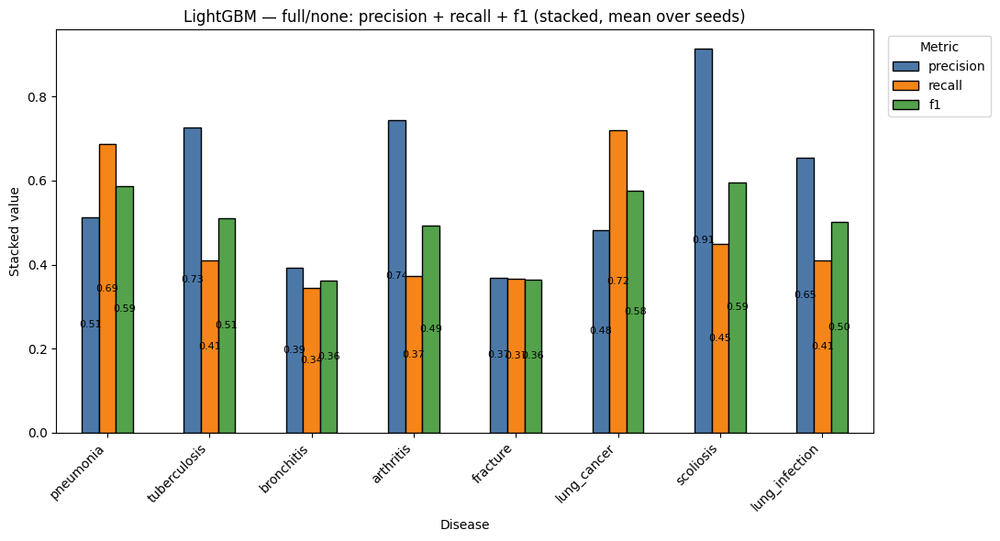

In [13]:
import os, pandas as pd, numpy as np, matplotlib.pyplot as plt

MODEL   = 'LightGBM'
ARCH    = 'full'
AUG     = 'none'          # <-- đổi thành augmenter của scenario bạn muốn: none/smotenc/gsmote/adasyn/ctgan/...
METRICS = ['precision', 'recall', 'f1']

res = pd.read_csv(os.path.join(RESULTS_DIR, RESULTS_NAME))
d = res[(res.Model == MODEL) & (res.arch == ARCH) & (res.augmenter == AUG)]

if d.empty:
    print('Không có dữ liệu cho', MODEL, ARCH, AUG, '— kiểm tra lại tên augmenter/đã chạy chưa')
else:
    order = [x for x in diseases if x in set(d['Disease'])]
    g = d.groupby('Disease')[METRICS].mean().reindex(order)

    ax = g.plot(kind='bar', stacked=False, figsize=(11, 6),
                color=['#4C78A8', '#F58518', '#54A24B'], edgecolor='black')
    ax.set_title(f'{MODEL} — {ARCH}/{AUG}: precision + recall + f1 (stacked, mean over seeds)')
    ax.set_xlabel('Disease'); ax.set_ylabel('Stacked value')
    plt.xticks(rotation=45, ha='right')
    for c in ax.containers:                      # ghi số lên từng đoạn
        ax.bar_label(c, fmt='%.2f', label_type='center', fontsize=8)
    ax.legend(title='Metric', bbox_to_anchor=(1.01, 1), loc='upper left')
    plt.tight_layout(); plt.show()


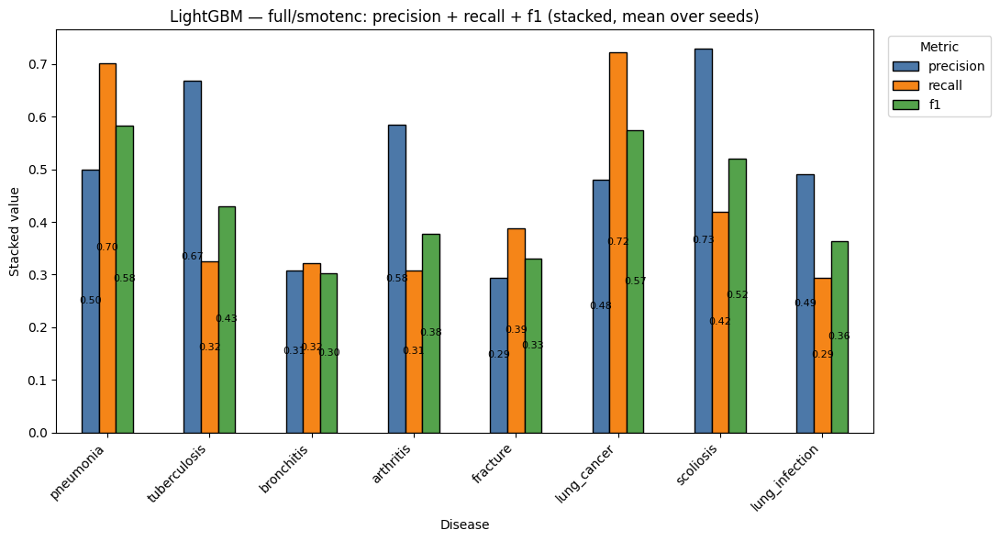

In [14]:
import os, pandas as pd, numpy as np, matplotlib.pyplot as plt

MODEL   = 'LightGBM'
ARCH    = 'full'
AUG     = 'smotenc'          # <-- đổi thành augmenter của scenario bạn muốn: none/smotenc/gsmote/adasyn/ctgan/...
METRICS = ['precision', 'recall', 'f1']

res = pd.read_csv(os.path.join(RESULTS_DIR, RESULTS_NAME))
d = res[(res.Model == MODEL) & (res.arch == ARCH) & (res.augmenter == AUG)]

if d.empty:
    print('Không có dữ liệu cho', MODEL, ARCH, AUG, '— kiểm tra lại tên augmenter/đã chạy chưa')
else:
    order = [x for x in diseases if x in set(d['Disease'])]
    g = d.groupby('Disease')[METRICS].mean().reindex(order)

    ax = g.plot(kind='bar', stacked=False, figsize=(11, 6),
                color=['#4C78A8', '#F58518', '#54A24B'], edgecolor='black')
    ax.set_title(f'{MODEL} — {ARCH}/{AUG}: precision + recall + f1 (stacked, mean over seeds)')
    ax.set_xlabel('Disease'); ax.set_ylabel('Stacked value')
    plt.xticks(rotation=45, ha='right')
    for c in ax.containers:                      # ghi số lên từng đoạn
        ax.bar_label(c, fmt='%.2f', label_type='center', fontsize=8)
    ax.legend(title='Metric', bbox_to_anchor=(1.01, 1), loc='upper left')
    plt.tight_layout(); plt.show()


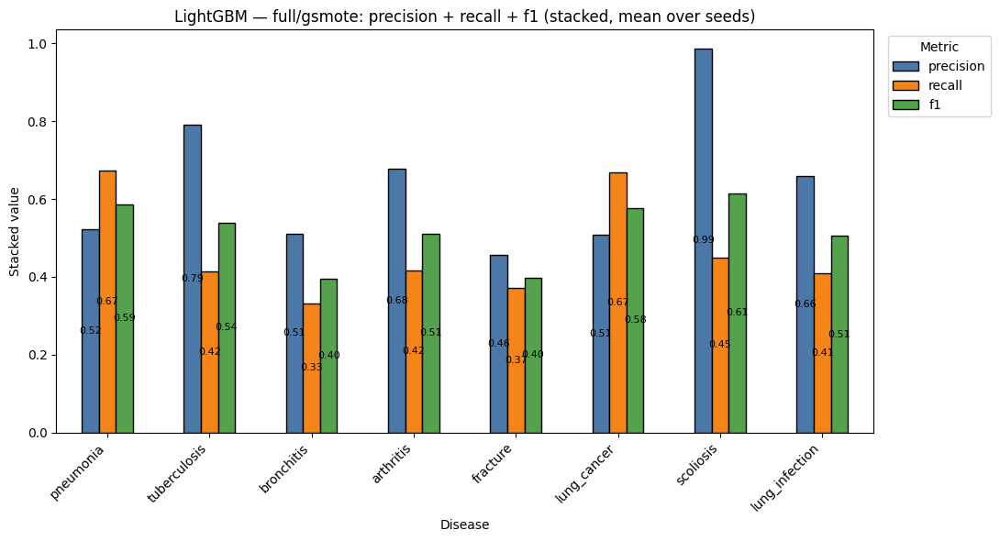

In [12]:
import os, pandas as pd, numpy as np, matplotlib.pyplot as plt

MODEL   = 'LightGBM'
ARCH    = 'full'
AUG     = 'gsmote'          # <-- đổi thành augmenter của scenario bạn muốn: none/smotenc/gsmote/adasyn/ctgan/...
METRICS = ['precision', 'recall', 'f1']

res = pd.read_csv(os.path.join(RESULTS_DIR, RESULTS_NAME))
d = res[(res.Model == MODEL) & (res.arch == ARCH) & (res.augmenter == AUG)]

if d.empty:
    print('Không có dữ liệu cho', MODEL, ARCH, AUG, '— kiểm tra lại tên augmenter/đã chạy chưa')
else:
    order = [x for x in diseases if x in set(d['Disease'])]
    g = d.groupby('Disease')[METRICS].mean().reindex(order)

    ax = g.plot(kind='bar', stacked=False, figsize=(11, 6),
                color=['#4C78A8', '#F58518', '#54A24B'], edgecolor='black')
    ax.set_title(f'{MODEL} — {ARCH}/{AUG}: precision + recall + f1 (stacked, mean over seeds)')
    ax.set_xlabel('Disease'); ax.set_ylabel('Stacked value')
    plt.xticks(rotation=45, ha='right')
    for c in ax.containers:                      # ghi số lên từng đoạn
        ax.bar_label(c, fmt='%.2f', label_type='center', fontsize=8)
    ax.legend(title='Metric', bbox_to_anchor=(1.01, 1), loc='upper left')
    plt.tight_layout(); plt.show()


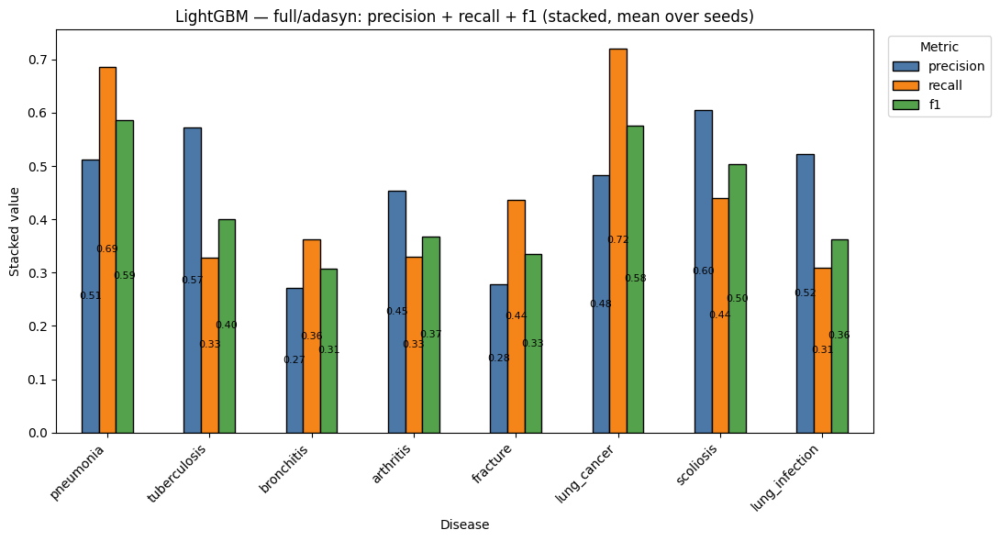

In [16]:
import os, pandas as pd, numpy as np, matplotlib.pyplot as plt

MODEL   = 'LightGBM'
ARCH    = 'full'
AUG     = 'adasyn'          # <-- đổi thành augmenter của scenario bạn muốn: none/smotenc/gsmote/adasyn/ctgan/...
METRICS = ['precision', 'recall', 'f1']

res = pd.read_csv(os.path.join(RESULTS_DIR, RESULTS_NAME))
d = res[(res.Model == MODEL) & (res.arch == ARCH) & (res.augmenter == AUG)]

if d.empty:
    print('Không có dữ liệu cho', MODEL, ARCH, AUG, '— kiểm tra lại tên augmenter/đã chạy chưa')
else:
    order = [x for x in diseases if x in set(d['Disease'])]
    g = d.groupby('Disease')[METRICS].mean().reindex(order)

    ax = g.plot(kind='bar', stacked=False, figsize=(11, 6),
                color=['#4C78A8', '#F58518', '#54A24B'], edgecolor='black')
    ax.set_title(f'{MODEL} — {ARCH}/{AUG}: precision + recall + f1 (stacked, mean over seeds)')
    ax.set_xlabel('Disease'); ax.set_ylabel('Stacked value')
    plt.xticks(rotation=45, ha='right')
    for c in ax.containers:                      # ghi số lên từng đoạn
        ax.bar_label(c, fmt='%.2f', label_type='center', fontsize=8)
    ax.legend(title='Metric', bbox_to_anchor=(1.01, 1), loc='upper left')
    plt.tight_layout(); plt.show()


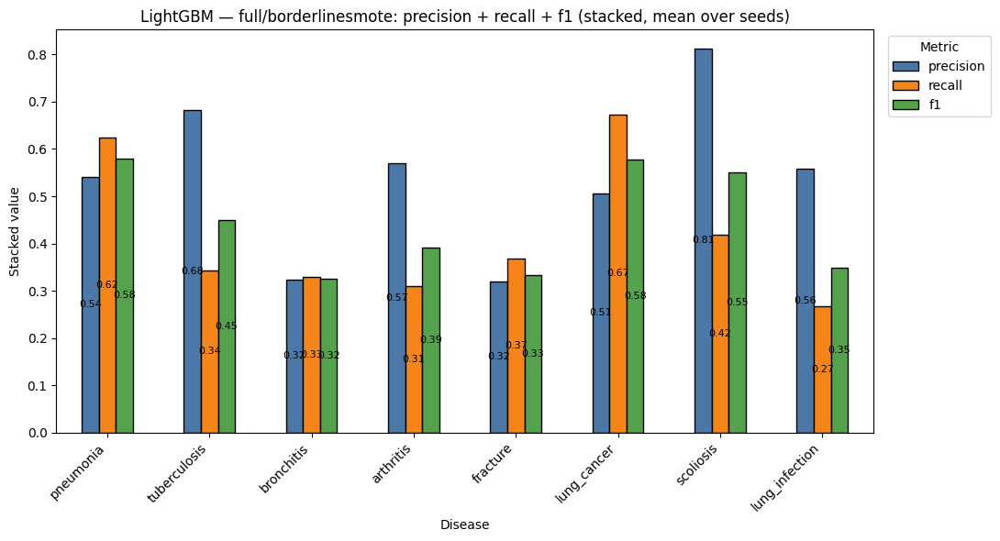

In [17]:
import os, pandas as pd, numpy as np, matplotlib.pyplot as plt

MODEL   = 'LightGBM'
ARCH    = 'full'
AUG     = 'borderlinesmote'          # <-- đổi thành augmenter của scenario bạn muốn: none/smotenc/gsmote/adasyn/ctgan/...
METRICS = ['precision', 'recall', 'f1']

res = pd.read_csv(os.path.join(RESULTS_DIR, RESULTS_NAME))
d = res[(res.Model == MODEL) & (res.arch == ARCH) & (res.augmenter == AUG)]

if d.empty:
    print('Không có dữ liệu cho', MODEL, ARCH, AUG, '— kiểm tra lại tên augmenter/đã chạy chưa')
else:
    order = [x for x in diseases if x in set(d['Disease'])]
    g = d.groupby('Disease')[METRICS].mean().reindex(order)

    ax = g.plot(kind='bar', stacked=False, figsize=(11, 6),
                color=['#4C78A8', '#F58518', '#54A24B'], edgecolor='black')
    ax.set_title(f'{MODEL} — {ARCH}/{AUG}: precision + recall + f1 (stacked, mean over seeds)')
    ax.set_xlabel('Disease'); ax.set_ylabel('Stacked value')
    plt.xticks(rotation=45, ha='right')
    for c in ax.containers:                      # ghi số lên từng đoạn
        ax.bar_label(c, fmt='%.2f', label_type='center', fontsize=8)
    ax.legend(title='Metric', bbox_to_anchor=(1.01, 1), loc='upper left')
    plt.tight_layout(); plt.show()


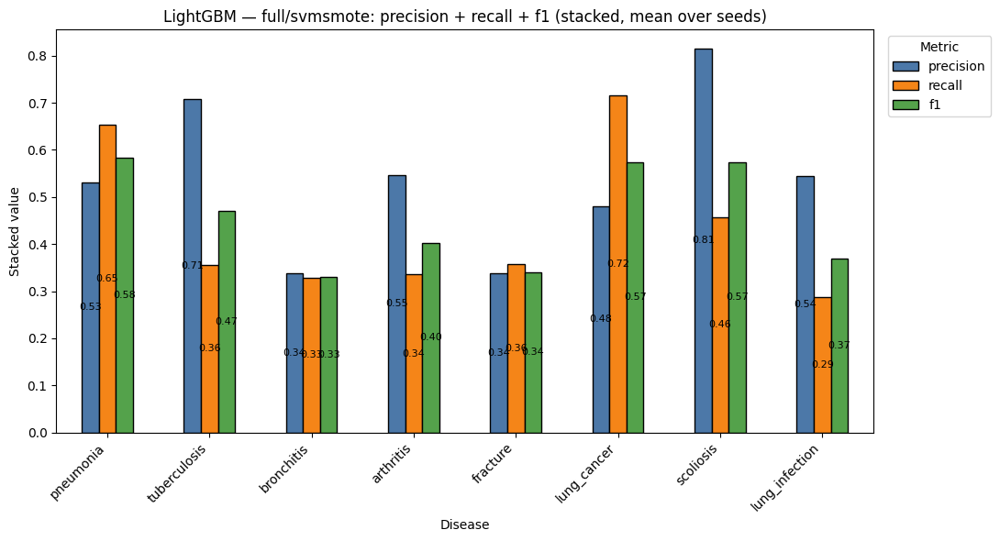

In [18]:
import os, pandas as pd, numpy as np, matplotlib.pyplot as plt

MODEL   = 'LightGBM'
ARCH    = 'full'
AUG     = 'svmsmote'          # <-- đổi thành augmenter của scenario bạn muốn: none/smotenc/gsmote/adasyn/ctgan/...
METRICS = ['precision', 'recall', 'f1']

res = pd.read_csv(os.path.join(RESULTS_DIR, RESULTS_NAME))
d = res[(res.Model == MODEL) & (res.arch == ARCH) & (res.augmenter == AUG)]

if d.empty:
    print('Không có dữ liệu cho', MODEL, ARCH, AUG, '— kiểm tra lại tên augmenter/đã chạy chưa')
else:
    order = [x for x in diseases if x in set(d['Disease'])]
    g = d.groupby('Disease')[METRICS].mean().reindex(order)

    ax = g.plot(kind='bar', stacked=False, figsize=(11, 6),
                color=['#4C78A8', '#F58518', '#54A24B'], edgecolor='black')
    ax.set_title(f'{MODEL} — {ARCH}/{AUG}: precision + recall + f1 (stacked, mean over seeds)')
    ax.set_xlabel('Disease'); ax.set_ylabel('Stacked value')
    plt.xticks(rotation=45, ha='right')
    for c in ax.containers:                      # ghi số lên từng đoạn
        ax.bar_label(c, fmt='%.2f', label_type='center', fontsize=8)
    ax.legend(title='Metric', bbox_to_anchor=(1.01, 1), loc='upper left')
    plt.tight_layout(); plt.show()


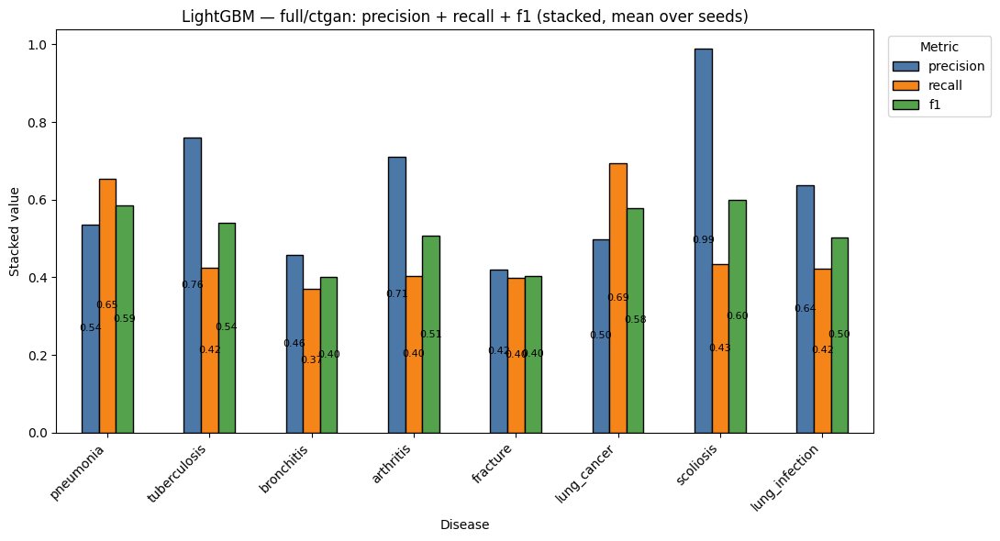

In [20]:
import os, pandas as pd, numpy as np, matplotlib.pyplot as plt

MODEL   = 'LightGBM'
ARCH    = 'full'
AUG     = 'ctgan'          # <-- đổi thành augmenter của scenario bạn muốn: none/smotenc/gsmote/adasyn/ctgan/...
METRICS = ['precision', 'recall', 'f1']

res = pd.read_csv(os.path.join(RESULTS_DIR, RESULTS_NAME))
d = res[(res.Model == MODEL) & (res.arch == ARCH) & (res.augmenter == AUG)]

if d.empty:
    print('Không có dữ liệu cho', MODEL, ARCH, AUG, '— kiểm tra lại tên augmenter/đã chạy chưa')
else:
    order = [x for x in diseases if x in set(d['Disease'])]
    g = d.groupby('Disease')[METRICS].mean().reindex(order)

    ax = g.plot(kind='bar', stacked=False, figsize=(11, 6),
                color=['#4C78A8', '#F58518', '#54A24B'], edgecolor='black')
    ax.set_title(f'{MODEL} — {ARCH}/{AUG}: precision + recall + f1 (stacked, mean over seeds)')
    ax.set_xlabel('Disease'); ax.set_ylabel('Stacked value')
    plt.xticks(rotation=45, ha='right')
    for c in ax.containers:                      # ghi số lên từng đoạn
        ax.bar_label(c, fmt='%.2f', label_type='center', fontsize=8)
    ax.legend(title='Metric', bbox_to_anchor=(1.01, 1), loc='upper left')
    plt.tight_layout(); plt.show()


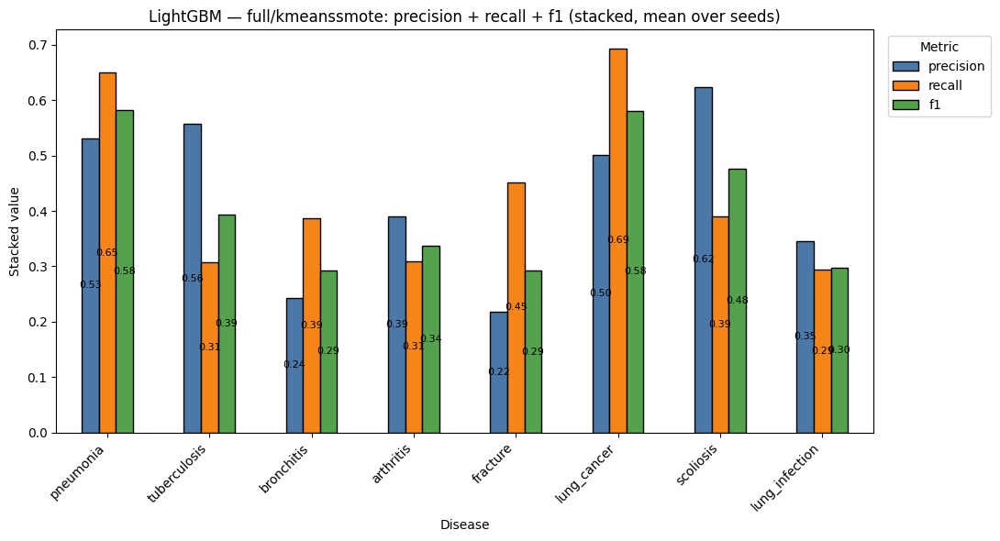

In [23]:
import os, pandas as pd, numpy as np, matplotlib.pyplot as plt

MODEL   = 'LightGBM'
ARCH    = 'full'
AUG     = 'kmeanssmote'          # <-- đổi thành augmenter của scenario bạn muốn: none/smotenc/gsmote/adasyn/ctgan/...
METRICS = ['precision', 'recall', 'f1']

res = pd.read_csv(os.path.join(RESULTS_DIR, RESULTS_NAME))
d = res[(res.Model == MODEL) & (res.arch == ARCH) & (res.augmenter == AUG)]

if d.empty:
    print('Không có dữ liệu cho', MODEL, ARCH, AUG, '— kiểm tra lại tên augmenter/đã chạy chưa')
else:
    order = [x for x in diseases if x in set(d['Disease'])]
    g = d.groupby('Disease')[METRICS].mean().reindex(order)

    ax = g.plot(kind='bar', stacked=False, figsize=(11, 6),
                color=['#4C78A8', '#F58518', '#54A24B'], edgecolor='black')
    ax.set_title(f'{MODEL} — {ARCH}/{AUG}: precision + recall + f1 (stacked, mean over seeds)')
    ax.set_xlabel('Disease'); ax.set_ylabel('Stacked value')
    plt.xticks(rotation=45, ha='right')
    for c in ax.containers:                      # ghi số lên từng đoạn
        ax.bar_label(c, fmt='%.2f', label_type='center', fontsize=8)
    ax.legend(title='Metric', bbox_to_anchor=(1.01, 1), loc='upper left')
    plt.tight_layout(); plt.show()


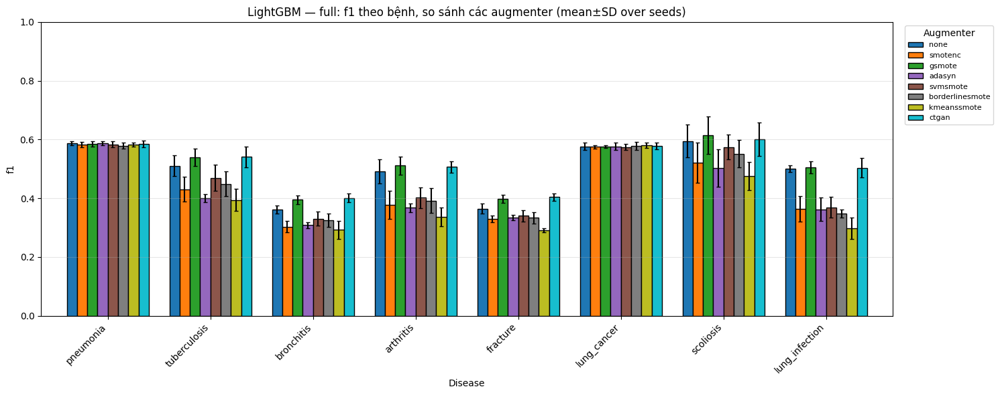

In [24]:
import os, pandas as pd, numpy as np, matplotlib.pyplot as plt

MODEL   = 'LightGBM'
ARCH    = 'full'
METRIC  = 'f1'              # đổi: 'precision' / 'recall' / 'auroc' / 'accuracy'
AUG_ORDER = ['none','smotenc','gsmote','adasyn','svmsmote','borderlinesmote','kmeanssmote','ctgan','ctabganplus']

res = pd.read_csv(os.path.join(RESULTS_DIR, RESULTS_NAME))
d = res[(res.Model == MODEL) & (res.arch == ARCH)]

if d.empty:
    print('Không có dữ liệu cho', MODEL, ARCH)
else:
    augs = [a for a in AUG_ORDER if a in set(d['augmenter'])]
    rows = [x for x in diseases if x in set(d['Disease'])]
    piv  = d.groupby(['Disease','augmenter'])[METRIC].mean().unstack()[augs].reindex(rows)
    err  = d.groupby(['Disease','augmenter'])[METRIC].std().unstack()[augs].reindex(rows)

    ax = piv.plot(kind='bar', yerr=err, capsize=2, figsize=(15, 6),
                  colormap='tab10', edgecolor='black', width=0.8)
    ax.set_title(f'{MODEL} — {ARCH}: {METRIC} theo bệnh, so sánh các augmenter (mean±SD over seeds)')
    ax.set_xlabel('Disease'); ax.set_ylabel(METRIC); ax.set_ylim(0, 1)
    plt.xticks(rotation=45, ha='right')
    ax.legend(title='Augmenter', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
    ax.grid(axis='y', alpha=.3)
    plt.tight_layout(); plt.show()


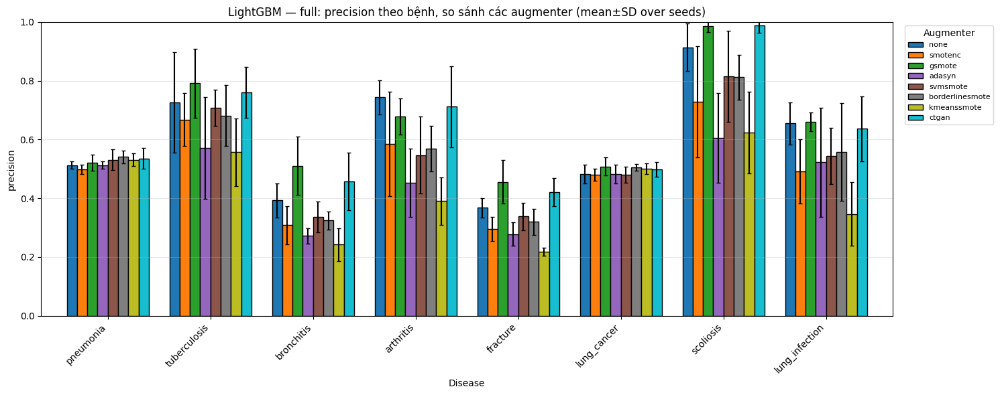

In [25]:
import os, pandas as pd, numpy as np, matplotlib.pyplot as plt

MODEL   = 'LightGBM'
ARCH    = 'full'
METRIC  = 'precision'              # đổi: 'precision' / 'recall' / 'auroc' / 'accuracy'
AUG_ORDER = ['none','smotenc','gsmote','adasyn','svmsmote','borderlinesmote','kmeanssmote','ctgan','ctabganplus']

res = pd.read_csv(os.path.join(RESULTS_DIR, RESULTS_NAME))
d = res[(res.Model == MODEL) & (res.arch == ARCH)]

if d.empty:
    print('Không có dữ liệu cho', MODEL, ARCH)
else:
    augs = [a for a in AUG_ORDER if a in set(d['augmenter'])]
    rows = [x for x in diseases if x in set(d['Disease'])]
    piv  = d.groupby(['Disease','augmenter'])[METRIC].mean().unstack()[augs].reindex(rows)
    err  = d.groupby(['Disease','augmenter'])[METRIC].std().unstack()[augs].reindex(rows)

    ax = piv.plot(kind='bar', yerr=err, capsize=2, figsize=(15, 6),
                  colormap='tab10', edgecolor='black', width=0.8)
    ax.set_title(f'{MODEL} — {ARCH}: {METRIC} theo bệnh, so sánh các augmenter (mean±SD over seeds)')
    ax.set_xlabel('Disease'); ax.set_ylabel(METRIC); ax.set_ylim(0, 1)
    plt.xticks(rotation=45, ha='right')
    ax.legend(title='Augmenter', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
    ax.grid(axis='y', alpha=.3)
    plt.tight_layout(); plt.show()


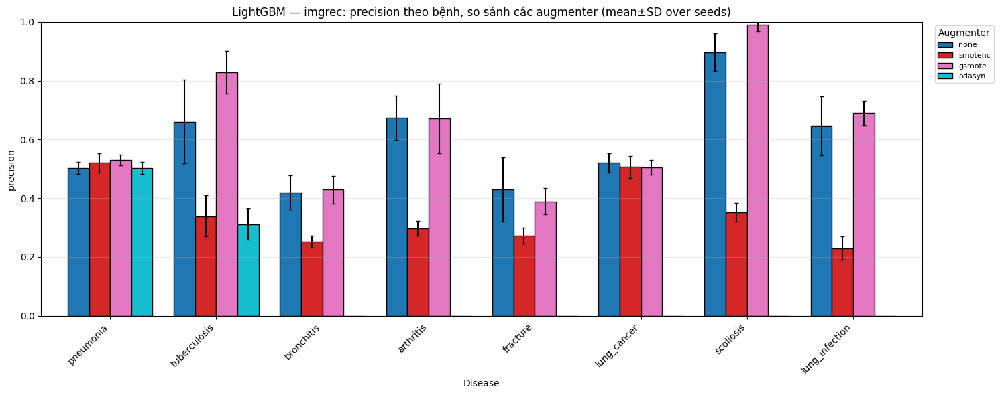

In [35]:
import os, pandas as pd, numpy as np, matplotlib.pyplot as plt

MODEL   = 'LightGBM'
ARCH    = 'imgrec'
METRIC  = 'precision'              # đổi: 'precision' / 'recall' / 'auroc' / 'accuracy'
AUG_ORDER = ['none','smotenc','gsmote','adasyn','svmsmote','borderlinesmote','kmeanssmote','ctgan','ctabganplus']

res = pd.read_csv(os.path.join(RESULTS_DIR, RESULTS_NAME))
d = res[(res.Model == MODEL) & (res.arch == ARCH)]

if d.empty:
    print('Không có dữ liệu cho', MODEL, ARCH)
else:
    augs = [a for a in AUG_ORDER if a in set(d['augmenter'])]
    rows = [x for x in diseases if x in set(d['Disease'])]
    piv  = d.groupby(['Disease','augmenter'])[METRIC].mean().unstack()[augs].reindex(rows)
    err  = d.groupby(['Disease','augmenter'])[METRIC].std().unstack()[augs].reindex(rows)

    ax = piv.plot(kind='bar', yerr=err, capsize=2, figsize=(15, 6),
                  colormap='tab10', edgecolor='black', width=0.8)
    ax.set_title(f'{MODEL} — {ARCH}: {METRIC} theo bệnh, so sánh các augmenter (mean±SD over seeds)')
    ax.set_xlabel('Disease'); ax.set_ylabel(METRIC); ax.set_ylim(0, 1)
    plt.xticks(rotation=45, ha='right')
    ax.legend(title='Augmenter', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
    ax.grid(axis='y', alpha=.3)
    plt.tight_layout(); plt.show()


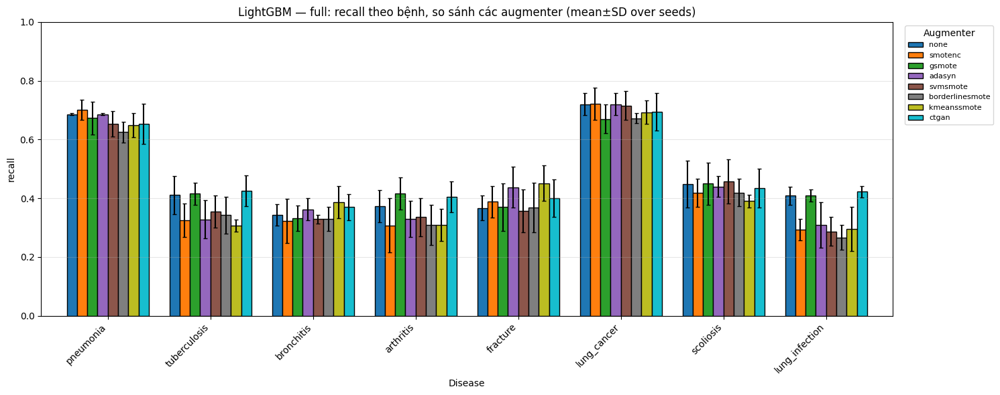

In [26]:
import os, pandas as pd, numpy as np, matplotlib.pyplot as plt

MODEL   = 'LightGBM'
ARCH    = 'full'
METRIC  = 'recall'              # đổi: 'precision' / 'recall' / 'auroc' / 'accuracy'
AUG_ORDER = ['none','smotenc','gsmote','adasyn','svmsmote','borderlinesmote','kmeanssmote','ctgan','ctabganplus']

res = pd.read_csv(os.path.join(RESULTS_DIR, RESULTS_NAME))
d = res[(res.Model == MODEL) & (res.arch == ARCH)]

if d.empty:
    print('Không có dữ liệu cho', MODEL, ARCH)
else:
    augs = [a for a in AUG_ORDER if a in set(d['augmenter'])]
    rows = [x for x in diseases if x in set(d['Disease'])]
    piv  = d.groupby(['Disease','augmenter'])[METRIC].mean().unstack()[augs].reindex(rows)
    err  = d.groupby(['Disease','augmenter'])[METRIC].std().unstack()[augs].reindex(rows)

    ax = piv.plot(kind='bar', yerr=err, capsize=2, figsize=(15, 6),
                  colormap='tab10', edgecolor='black', width=0.8)
    ax.set_title(f'{MODEL} — {ARCH}: {METRIC} theo bệnh, so sánh các augmenter (mean±SD over seeds)')
    ax.set_xlabel('Disease'); ax.set_ylabel(METRIC); ax.set_ylim(0, 1)
    plt.xticks(rotation=45, ha='right')
    ax.legend(title='Augmenter', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
    ax.grid(axis='y', alpha=.3)
    plt.tight_layout(); plt.show()


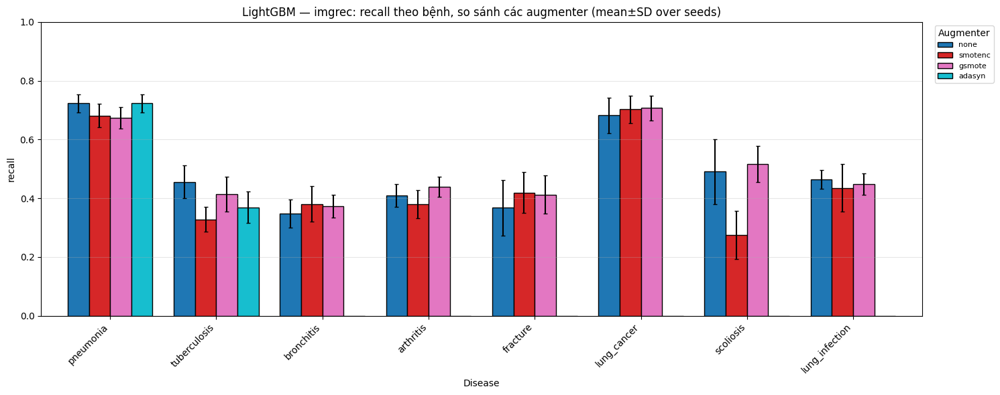

In [37]:
import os, pandas as pd, numpy as np, matplotlib.pyplot as plt

MODEL   = 'LightGBM'
ARCH    = 'imgrec'
METRIC  = 'recall'              # đổi: 'precision' / 'recall' / 'auroc' / 'accuracy'
AUG_ORDER = ['none','smotenc','gsmote','adasyn','svmsmote','borderlinesmote','kmeanssmote','ctgan','ctabganplus']

res = pd.read_csv(os.path.join(RESULTS_DIR, RESULTS_NAME))
d = res[(res.Model == MODEL) & (res.arch == ARCH)]

if d.empty:
    print('Không có dữ liệu cho', MODEL, ARCH)
else:
    augs = [a for a in AUG_ORDER if a in set(d['augmenter'])]
    rows = [x for x in diseases if x in set(d['Disease'])]
    piv  = d.groupby(['Disease','augmenter'])[METRIC].mean().unstack()[augs].reindex(rows)
    err  = d.groupby(['Disease','augmenter'])[METRIC].std().unstack()[augs].reindex(rows)

    ax = piv.plot(kind='bar', yerr=err, capsize=2, figsize=(15, 6),
                  colormap='tab10', edgecolor='black', width=0.8)
    ax.set_title(f'{MODEL} — {ARCH}: {METRIC} theo bệnh, so sánh các augmenter (mean±SD over seeds)')
    ax.set_xlabel('Disease'); ax.set_ylabel(METRIC); ax.set_ylim(0, 1)
    plt.xticks(rotation=45, ha='right')
    ax.legend(title='Augmenter', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
    ax.grid(axis='y', alpha=.3)
    plt.tight_layout(); plt.show()


In [28]:
import os, numpy as np, pandas as pd

roc_d = load_roc()
_trapz = np.trapezoid if hasattr(np, 'trapezoid') else np.trapz   # <-- sửa ở đây

def _test_prev(disease, seed):
    tr, te, va, *_ = get_split(int(seed))
    return float(df[disease].iloc[te].astype(int).mean())

def _auprc_from_roc(fpr, tpr, pi):
    fpr, tpr = np.asarray(fpr, float), np.asarray(tpr, float)
    prec = (tpr * pi) / (tpr * pi + fpr * (1 - pi) + 1e-12)
    o = np.argsort(tpr)
    return float(_trapz(prec[o], tpr[o]))

res = pd.read_csv(os.path.join(RESULTS_DIR, RESULTS_NAME))
auprc = []
for _, r in res.iterrows():
    v = roc_d.get((r.Disease, r.arch, r.augmenter, r.Model, int(r.seed)))
    auprc.append(_auprc_from_roc(v['fpr'], v['tpr'], _test_prev(r.Disease, r.seed)) if v else np.nan)
res['auprc'] = auprc
res.to_csv(os.path.join(RESULTS_DIR, RESULTS_NAME), index=False)
print('đã thêm auprc:', res['auprc'].notna().sum(), '/', len(res))
print(res.groupby(['arch','augmenter'])['auprc'].mean().round(3).to_string())


đã thêm auprc: 4032 / 4032
arch    augmenter      
full    adasyn             0.257
        borderlinesmote    0.281
        ctgan              0.314
        gsmote             0.321
        kmeanssmote        0.243
        none               0.309
        smotenc            0.272
        svmsmote           0.298
imgrec  adasyn             0.366
        gsmote             0.332
        none               0.312
        smotenc            0.198


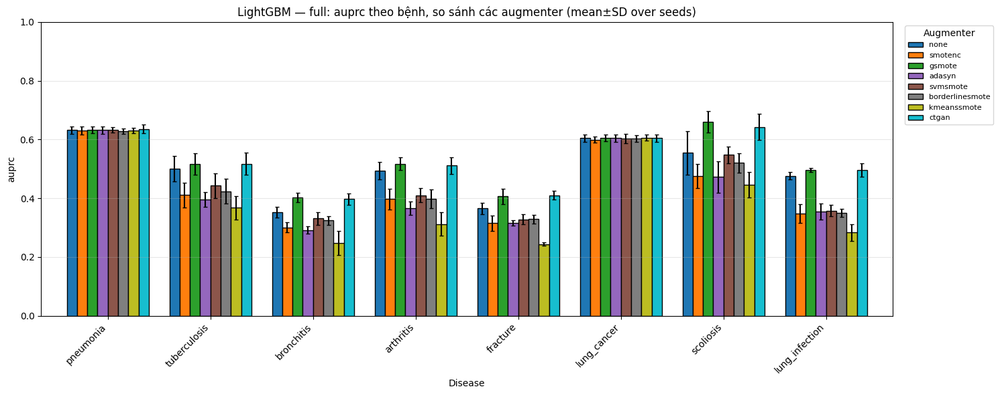

In [29]:
import os, pandas as pd, numpy as np, matplotlib.pyplot as plt

MODEL   = 'LightGBM'
ARCH    = 'full'
METRIC  = 'auprc'              # đổi: 'precision' / 'recall' / 'auroc' / 'accuracy'
AUG_ORDER = ['none','smotenc','gsmote','adasyn','svmsmote','borderlinesmote','kmeanssmote','ctgan','ctabganplus']

res = pd.read_csv(os.path.join(RESULTS_DIR, RESULTS_NAME))
d = res[(res.Model == MODEL) & (res.arch == ARCH)]

if d.empty:
    print('Không có dữ liệu cho', MODEL, ARCH)
else:
    augs = [a for a in AUG_ORDER if a in set(d['augmenter'])]
    rows = [x for x in diseases if x in set(d['Disease'])]
    piv  = d.groupby(['Disease','augmenter'])[METRIC].mean().unstack()[augs].reindex(rows)
    err  = d.groupby(['Disease','augmenter'])[METRIC].std().unstack()[augs].reindex(rows)

    ax = piv.plot(kind='bar', yerr=err, capsize=2, figsize=(15, 6),
                  colormap='tab10', edgecolor='black', width=0.8)
    ax.set_title(f'{MODEL} — {ARCH}: {METRIC} theo bệnh, so sánh các augmenter (mean±SD over seeds)')
    ax.set_xlabel('Disease'); ax.set_ylabel(METRIC); ax.set_ylim(0, 1)
    plt.xticks(rotation=45, ha='right')
    ax.legend(title='Augmenter', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
    ax.grid(axis='y', alpha=.3)
    plt.tight_layout(); plt.show()


In [19]:
print('IN_KAGGLE :', IN_KAGGLE)
print('_KAGGLE_OK :', _KAGGLE_OK)
print('DATASET_ID :', DATASET_ID)
import os
print('working dir:', os.path.abspath(RESULTS_DIR))
print('files      :', os.listdir(RESULTS_DIR) if os.path.isdir(RESULTS_DIR) else 'MISSING')


IN_KAGGLE : True
_KAGGLE_OK : True
DATASET_ID : tuanducngo/approach1-iterimp-ckpt
working dir: /kaggle/working/results_approach1
files      : ['approach1-iterimp-ckpt.zip']


In [29]:
import pandas as pd
RESULTS_CSV = "/kaggle/working/results_approach1/results_approach1_iterimp.csv"
results = pd.read_csv(RESULTS_CSV)
print("Loaded", results.shape, "rows từ checkpoint (không cần train lại)")


Loaded (4034, 14) rows từ checkpoint (không cần train lại)


In [30]:
import os, glob
import pandas as pd

# # === Load đã-chạy results từ Kaggle dataset (thay vì chờ train xong) ===
# LOAD_FROM_KAGGLE = True          # bật/tắt
# RESULTS_CSV = None               # đặt đường dẫn cụ thể nếu muốn, vd:
#                                  # "/kaggle/input/my-results/results.csv"

# def load_saved_results():
#     # 1) nếu chỉ định thẳng 1 file
#     if RESULTS_CSV and os.path.exists(RESULTS_CSV):
#         return pd.read_csv(RESULTS_CSV)

#     # 2) tự quét mọi CSV trong các dataset input của Kaggle
#     candidates = glob.glob('/kaggle/input/**/*.csv', recursive=True)
#     need = {'Disease', 'arch', 'augmenter', 'Model', 'f1'}
#     frames = []
#     for f in candidates:
#         try:
#             df = pd.read_csv(f)
#         except Exception:
#             continue
#         if need.issubset(df.columns):        # chỉ lấy CSV đúng schema
#             df['__src'] = os.path.basename(f)
#             frames.append(df)
#     if not frames:
#         raise FileNotFoundError(
#             f"Không thấy CSV kết quả trong /kaggle/input. "
#             f"CSV cần có các cột: {need}. Các file tìm thấy: {candidates}")
#     out = pd.concat(frames, ignore_index=True)
#     print(f"Loaded {len(out)} rows từ {out['__src'].nunique()} file: "
#           f"{sorted(out['__src'].unique())}")
#     return out

if LOAD_FROM_KAGGLE:
    results = load_saved_results()
    print("results shape:", results.shape)
    print("cols:", list(results.columns))


results shape: (4034, 14)
cols: ['Disease', 'arch', 'augmenter', 'Model', 'seed', 'aug_ratio', 'threshold', 'precision', 'recall', 'f1', 'accuracy', 'auroc', 'val_f1', 'stack_members']


In [31]:
# === Cross-scenario summary: best (augmenter, classifier) per disease by F1 ===
def best_per_disease(dfres, metric='f1'):
    g = dfres.groupby(['Disease', 'arch', 'augmenter', 'Model'])[metric].mean().reset_index()
    idx = g.groupby('Disease')[metric].idxmax()
    return g.loc[idx].sort_values('Disease').reset_index(drop=True)

if len(results):
    print('Best config per disease (by mean F1 class 1):')
    print(best_per_disease(results, 'f1').to_string(index=False))
    print('\nMean F1 by (arch, augmenter, Model) — top 15:')
    top = (results.groupby(['arch', 'augmenter', 'Model'])['f1'].mean()
           .sort_values(ascending=False).head(15))
    print(top.to_string())

    # Does Stacking beat its members? compare Stacking vs best base per (disease,arch,augmenter)
    base = results[results['Model'] != 'Stacking'].groupby(
        ['Disease', 'arch', 'augmenter'])['f1'].max().rename('best_base')
    stk = results[results['Model'] == 'Stacking'].groupby(
        ['Disease', 'arch', 'augmenter'])['f1'].mean().rename('stacking')
    cmp = pd.concat([base, stk], axis=1).dropna()
    cmp['stack_wins'] = cmp['stacking'] >= cmp['best_base']
    if len(cmp):
        print(f"\nStacking >= best single model in {cmp['stack_wins'].mean()*100:.0f}% of (disease,arch,aug) cells")


Best config per disease (by mean F1 class 1):
       Disease   arch augmenter    Model       f1
     arthritis imgrec    gsmote LightGBM 0.524816
    bronchitis   full     ctgan LightGBM 0.400905
      fracture   full     ctgan LightGBM 0.403825
   lung_cancer imgrec    gsmote Stacking 0.590496
lung_infection imgrec    gsmote LightGBM 0.541116
     pneumonia imgrec    gsmote LightGBM 0.593076
     scoliosis imgrec    gsmote LightGBM 0.676497
  tuberculosis imgrec    gsmote LightGBM 0.547834

Mean F1 by (arch, augmenter, Model) — top 15:
arch    augmenter        Model   
imgrec  gsmote           LightGBM    0.532965
        none             LightGBM    0.516053
full    gsmote           LightGBM    0.515549
        ctgan            LightGBM    0.514913
imgrec  none             Stacking    0.512848
        gsmote           Stacking    0.499362
full    none             LightGBM    0.498432
                         Stacking    0.496990
        ctgan            Stacking    0.486493
        g

In [33]:
# === Cross-scenario summary: best (augmenter, classifier) per disease by F1 ===
def best_per_disease(dfres, metric='precision'):
    g = dfres.groupby(['Disease', 'arch', 'augmenter', 'Model'])[metric].mean().reset_index()
    idx = g.groupby('Disease')[metric].idxmax()
    return g.loc[idx].sort_values('Disease').reset_index(drop=True)

if len(results):
    print('Best config per disease (by mean F1 class 1):')
    print(best_per_disease(results, 'precision').to_string(index=False))
    print('\nMean Precision by (arch, augmenter, Model) — top 15:')
    top = (results.groupby(['arch', 'augmenter', 'Model'])['precision'].mean()
           .sort_values(ascending=False).head(15))
    print(top.to_string())

    # Does Stacking beat its members? compare Stacking vs best base per (disease,arch,augmenter)
    base = results[results['Model'] != 'Stacking'].groupby(
        ['Disease', 'arch', 'augmenter'])['precision'].max().rename('best_base')
    stk = results[results['Model'] == 'Stacking'].groupby(
        ['Disease', 'arch', 'augmenter'])['precision'].mean().rename('stacking')
    cmp = pd.concat([base, stk], axis=1).dropna()
    cmp['stack_wins'] = cmp['stacking'] >= cmp['best_base']
    if len(cmp):
        print(f"\nStacking >= best single model in {cmp['stack_wins'].mean()*100:.0f}% of (disease,arch,aug) cells")


Best config per disease (by mean F1 class 1):
       Disease   arch augmenter    Model  precision
     arthritis   full     ctgan Stacking   0.773096
    bronchitis   full    gsmote Stacking   0.535316
      fracture   full    gsmote LightGBM   0.455379
   lung_cancer imgrec   smotenc Stacking   0.531023
lung_infection   full     ctgan Stacking   0.733528
     pneumonia imgrec    gsmote Stacking   0.546225
     scoliosis   full    gsmote Stacking   0.993333
  tuberculosis imgrec    gsmote LightGBM   0.828751

Mean Precision by (arch, augmenter, Model) — top 15:
arch    augmenter        Model   
full    gsmote           LightGBM    0.638899
imgrec  gsmote           LightGBM    0.629266
full    ctgan            LightGBM    0.626060
        gsmote           Stacking    0.625045
        ctgan            Stacking    0.617385
imgrec  gsmote           Stacking    0.606839
full    none             LightGBM    0.599249
imgrec  none             LightGBM    0.593861
full    none             Stack

In [34]:
# === Cross-scenario summary: best (augmenter, classifier) per disease by F1 ===
def best_per_disease(dfres, metric='recall'):
    g = dfres.groupby(['Disease', 'arch', 'augmenter', 'Model'])[metric].mean().reset_index()
    idx = g.groupby('Disease')[metric].idxmax()
    return g.loc[idx].sort_values('Disease').reset_index(drop=True)

if len(results):
    print('Best config per disease (by mean F1 class 1):')
    print(best_per_disease(results, 'recall').to_string(index=False))
    print('\nMean Recall by (arch, augmenter, Model) — top 15:')
    top = (results.groupby(['arch', 'augmenter', 'Model'])['recall'].mean()
           .sort_values(ascending=False).head(15))
    print(top.to_string())

    # Does Stacking beat its members? compare Stacking vs best base per (disease,arch,augmenter)
    base = results[results['Model'] != 'Stacking'].groupby(
        ['Disease', 'arch', 'augmenter'])['recall'].max().rename('best_base')
    stk = results[results['Model'] == 'Stacking'].groupby(
        ['Disease', 'arch', 'augmenter'])['recall'].mean().rename('stacking')
    cmp = pd.concat([base, stk], axis=1).dropna()
    cmp['stack_wins'] = cmp['stacking'] >= cmp['best_base']
    if len(cmp):
        print(f"\nStacking >= best single model in {cmp['stack_wins'].mean()*100:.0f}% of (disease,arch,aug) cells")


Best config per disease (by mean F1 class 1):
       Disease   arch   augmenter           Model   recall
     arthritis imgrec      gsmote IsolationForest 0.929439
    bronchitis   full kmeanssmote IsolationForest 0.966679
      fracture imgrec     smotenc IsolationForest 0.962513
   lung_cancer   full     smotenc IsolationForest 0.977156
lung_infection imgrec      gsmote IsolationForest 0.776884
     pneumonia   full kmeanssmote IsolationForest 0.986895
     scoliosis   full       ctgan IsolationForest 0.524364
  tuberculosis imgrec        none        LightGBM 0.455868

Mean Recall by (arch, augmenter, Model) — top 15:
arch    augmenter        Model          
imgrec  adasyn           IsolationForest    0.762229
full    kmeanssmote      IsolationForest    0.746494
        borderlinesmote  IsolationForest    0.744523
imgrec  gsmote           IsolationForest    0.739298
full    none             IsolationForest    0.730940
        ctgan            IsolationForest    0.730906
        svmsm